# Prédiction de la consommation de carburant avec les SVM

<div style="display: flex; justify-content: space-between; margin-bottom: 20px;">
  <div style="flex: 1;">
    <strong>Réalisé par :</strong> Homam DANY<br>
    <strong>Encadré par :</strong> Pr. AIT KBIR M'Hamed
  </div>
  <div style="flex: 1; text-align: right;">
    <strong>Module :</strong> Apprentissage Automatique<br>
    <strong>Année universitaire :</strong> 2026/2027
  </div>
</div>

---

## 1. Contexte et objectif

Le dataset **Auto MPG** contient des informations sur des voitures (poids, puissance,
cylindrée, année...) et leur consommation en **mpg** (miles per gallon, c'est-à-dire
le nombre de miles parcourus avec un gallon d'essence). Plus le mpg est élevé,
moins la voiture consomme.

On veut approximer la consommation à partir des caractéristiques du véhicule, de deux façons :

- **Classification (SVC)** : on transforme `mpg` en 3 classes (faible, moyenne, élevée)
  et on cherche à prédire la classe.
- **Régression (SVR)** : on prédit directement la valeur numérique de `mpg`.

Pour chaque approche, on code d'abord le modèle **à la main (from scratch)** avec numpy,
puis on compare avec l'implémentation de **scikit-learn**.

## 2. Rappel : c'est quoi un SVM ?

Un **SVM** (Support Vector Machine) cherche une **frontière de séparation** entre des classes.

- Pour deux classes, la frontière est une droite (en 2D) ou un hyperplan (en plus de dimensions) : `w·x + b = 0`.
- Il existe beaucoup de droites qui séparent les classes. Le SVM choisit celle qui a la
  **marge maximale**, c'est-à-dire la plus éloignée possible des points les plus proches
  de chaque classe.
- Les points qui touchent la marge s'appellent les **vecteurs de support**. Ce sont les seuls
  qui comptent pour définir la frontière.
- Si les classes ne sont pas parfaitement séparables, on autorise des erreurs avec un
  paramètre **C** (grand C = on tolère peu d'erreurs, petit C = on tolère plus d'erreurs).
- Si une droite ne suffit pas, on utilise un **noyau** (kernel, par exemple RBF) qui permet
  d'avoir une frontière courbe.

Pour la **régression (SVR)**, l'idée est différente : on cherche une droite qui passe
dans un "tube" de largeur **ε** (epsilon) autour des données. Les erreurs plus petites
que ε ne sont pas pénalisées.

L'essentiel pour l'instant  : *SVM = marge maximale + vecteurs de support + paramètre C + noyau*.

## 3. Imports et chargement des données

On commence par importer les bibliothèques :

- `numpy` : calcul sur les matrices et vecteurs (c'est avec lui qu'on codera les SVM).
- `pandas` : manipuler les données sous forme de tableau (DataFrame).
- `matplotlib` et `seaborn` : faire des graphiques. Seaborn sert aussi à charger le dataset.

In [ ]:
import numpy as np # pour les calculs scientifiques et le hasard
import pandas as pd # pour manipuler les données
import matplotlib.pyplot as plt # pour les graphiques
import seaborn as sns # pour des graphiques plus jolis

# un style un peu plus propre pour les graphiques
sns.set_theme(style="whitegrid")

# on fixe la graine du hasard pour avoir les mêmes résultats a chaque execution
np.random.seed(42)

In [2]:
# chargement du dataset depuis seaborn
df = sns.load_dataset("mpg")

# shape donne (nombre de lignes, nombre de colonnes)
print("Dimensions :", df.shape)

# head() affiche les 5 premieres lignes
df.head()

Dimensions : (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 4. Premier regard sur les données

Avant de faire quoi que ce soit, on regarde comment le tableau est fait. On utilise :

- `df.info()` : nom de chaque colonne, son **type** (float, int, object = texte) et le
  nombre de valeurs **non nulles**. Si ce nombre est plus petit que le nombre de lignes,
  c'est qu'il y a des valeurs manquantes.
- `df.describe()` : statistiques de base (moyenne, écart-type, min, max...) des colonnes numériques.
  Ça permet de voir les **échelles** : le poids est en milliers, l'accélération autour de 15.
  C'est important car les SVM sont sensibles aux échelles.

In [3]:
# types des colonnes et valeurs non nulles
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB


In [4]:
# statistiques des colonnes numeriques
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


## 5. Valeurs manquantes

Un modèle ne peut pas être entraîné avec des cases vides (scikit-learn renvoie une erreur,
et notre code from scratch donnerait des `nan`). On compte donc les valeurs manquantes
colonne par colonne.

In [5]:
# isna() met True quand la case est vide, sum() compte les True de chaque colonne
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

## 6. Nettoyage

Le dataset complet contient **398** lignes, mais le sujet parle de **392** échantillons.
La différence vient de la colonne `horsepower` qui a **6** valeurs manquantes.

On a deux options :
1. **Supprimer** ces lignes (on perd 6 voitures sur 398, soit environ 1,5 %).
2. **Imputer** : remplacer les cases vides par la moyenne ou la médiane.

On choisit de **supprimer**, car il y en a très peu et ça colle avec les 392 échantillons
du sujet. Ça évite aussi d'inventer des valeurs de puissance.

In [ ]:
# on garde l'ancienne taille pour pouvoir comparer
n_avant = len(df)

# dropna() supprime les lignes qui ont au moins une valeur manquante
df = df.dropna()

# apres suppression les index ont des "trous", on les remet a 0,1,2,...
df = df.reset_index(drop=True)
# on peut verifier que les lignes ont bien ete supprimees
print("Lignes avant :", n_avant)
print("Lignes apres :", len(df))
print("Valeurs manquantes restantes :", df.isna().sum().sum())

Lignes avant : 398
Lignes apres : 392
Valeurs manquantes restantes : 0


# Partie 2 : Exploration des données (EDA)

Dans cette partie, on cherche à répondre à 4 questions :

1. **Comment est répartie la cible `mpg` ?** (c'est elle qu'on découpera en classes plus tard)
2. **Comment sont réparties les variables explicatives ?** (échelles, valeurs extrêmes)
3. **Quelles variables sont liées à `mpg` ?** (corrélations)
4. **Les variables catégorielles (`cylinders`, `origin`) influencent-elles `mpg` ?**

On sépare d'abord les types de variables :
- **continues** : `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`
- **catégorielles** : `cylinders` (3, 4, 5, 6 ou 8) et `origin` (usa, japan, europe)
- `name` est juste le nom de la voiture, on ne l'utilisera pas comme variable.

In [7]:
# on met les noms de colonnes dans des listes, ca evite de les retaper partout
cols_continues = ["displacement", "horsepower", "weight", "acceleration", "model_year"]
cols_categ = ["cylinders", "origin"]

# combien de valeurs differentes dans chaque variable categorielle ?
for c in cols_categ:
    print(c, ":", df[c].nunique(), "valeurs ->", sorted(df[c].unique()))

cylinders : 5 valeurs -> [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(8)]
origin : 3 valeurs -> ['europe', 'japan', 'usa']


## 2.1 Distribution de la cible `mpg`

On trace un **histogramme** : on découpe l'axe des `mpg` en intervalles et on compte
combien de voitures tombent dans chacun.

Ça nous dit si la distribution est symétrique ou étalée d'un côté.

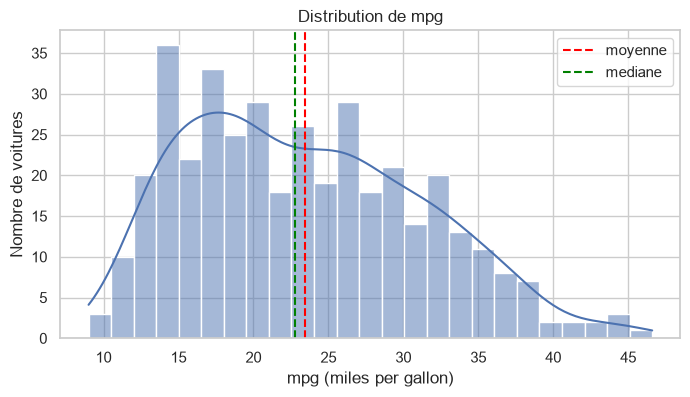

Moyenne : 23.45
Mediane : 22.75
Min / Max : 9.0 / 46.6


In [ ]:
plt.figure(figsize=(8, 4)) # taille du graphique

# kde=True ajoute une courbe lisse par dessus l'histogramme
sns.histplot(df["mpg"], bins=25, kde=True)

# lignes verticales pour la moyenne et la mediane
plt.axvline(df["mpg"].mean(), color="red", linestyle="--", label="moyenne")
plt.axvline(df["mpg"].median(), color="green", linestyle="--", label="mediane")

plt.title("Distribution de mpg")
plt.xlabel("mpg (miles per gallon)")
plt.ylabel("Nombre de voitures")
plt.legend()
plt.show()

print("Moyenne :", round(df["mpg"].mean(), 2))
print("Mediane :", round(df["mpg"].median(), 2))
print("Min / Max :", df["mpg"].min(), "/", df["mpg"].max())

## 2.2 Distribution des variables continues

On trace un histogramme pour chaque variable continue. On regarde surtout :
- les **échelles** très différentes (ex : `weight` en milliers, `acceleration` autour de 15) ;
- les distributions **asymétriques** (étalées d'un côté), comme `horsepower` ou `displacement`.

Les échelles différentes sont un vrai problème pour les SVM, car ils utilisent des
**distances** : une variable avec de grandes valeurs dominerait les autres.

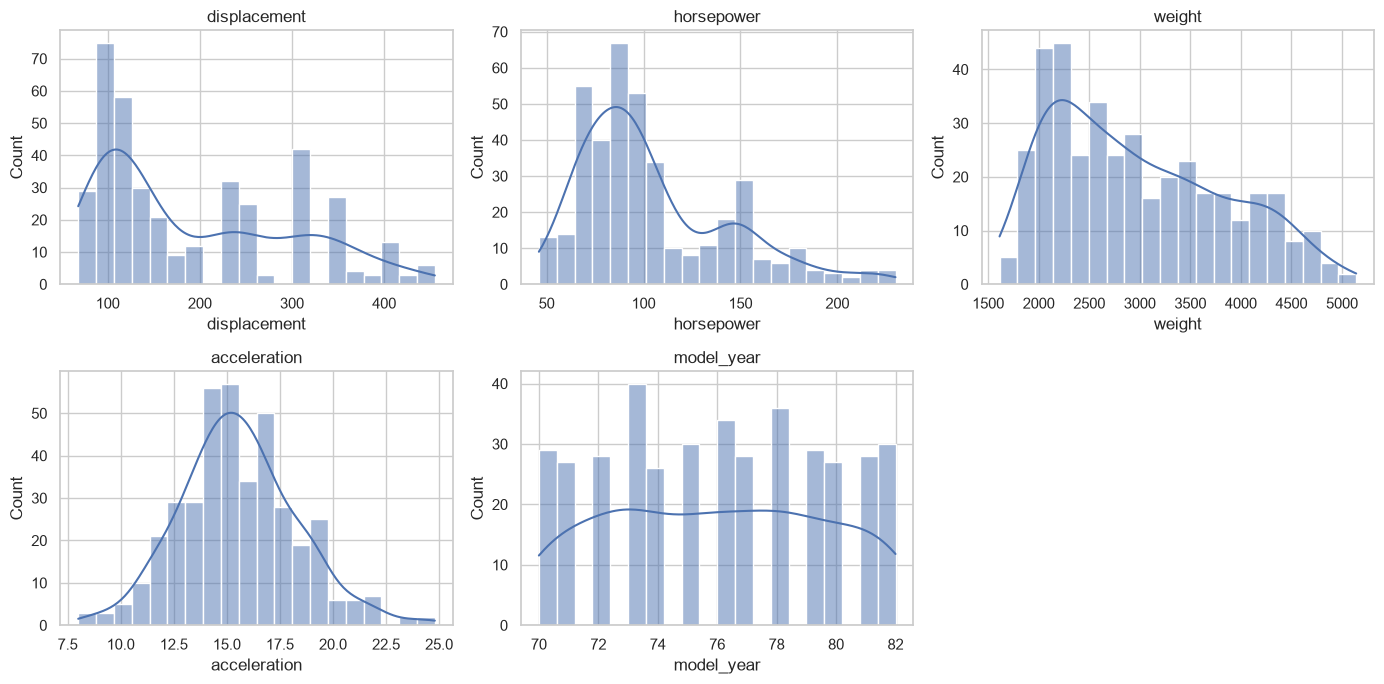

In [ ]:
# une grille de 2 lignes x 3 colonnes (la 6eme case restera vide)
fig, axes = plt.subplots(2, 3, figsize=(14, 7)) # taille du graphique
axes = axes.flatten()   # pour pouvoir les parcourir avec une seule boucle
# on fait un histogramme pour chaque variable continue
for i, col in enumerate(cols_continues):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[i])
    axes[i].set_title(col)

# on cache la case vide
axes[5].axis("off")

plt.tight_layout() # pour eviter que les titres se chevauchent
plt.show() # pour afficher le graphique

## 2.3 Variables catégorielles

Pour une variable qui prend peu de valeurs, on utilise un **diagramme en barres** (`countplot`)
qui compte le nombre de voitures par valeur.

Deux points à vérifier :
- Y a-t-il des modalités **très rares** ? (ex : 3 et 5 cylindres)
- Les modalités sont-elles **équilibrées** ?

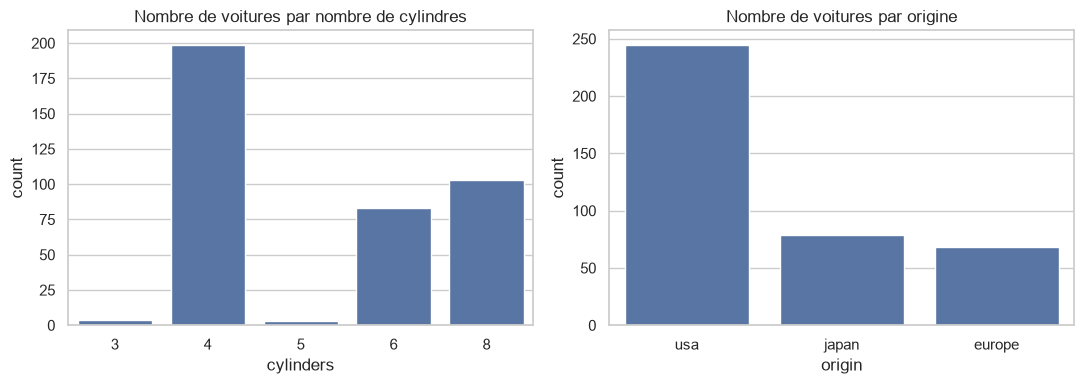

cylinders
4    199
8    103
6     83
3      4
5      3
Name: count, dtype: int64

origin
usa       245
japan      79
europe     68
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4)) # taille du graphique

sns.countplot(data=df, x="cylinders", ax=axes[0]) # on peut aussi mettre hue="origin" pour separer par origine
axes[0].set_title("Nombre de voitures par nombre de cylindres") # pour mettre un titre au graphique

sns.countplot(data=df, x="origin", ax=axes[1]) # sert a compter le nombre de voitures par origine
axes[1].set_title("Nombre de voitures par origine")

plt.tight_layout()
plt.show()

# les chiffres exacts
print(df["cylinders"].value_counts())
print()
print(df["origin"].value_counts())

## 2.4 Corrélations avec `mpg`

La **corrélation de Pearson** mesure la relation **linéaire** entre deux variables.
Elle va de -1 à +1 :
- proche de **-1** : quand l'une augmente, l'autre diminue ;
- proche de **+1** : elles augmentent ensemble ;
- proche de **0** : pas de relation linéaire.

On l'affiche dans une **matrice de corrélation** (heatmap). On y inclut `cylinders`
car c'est un nombre, mais on garde en tête que c'est une variable catégorielle.

**NB** : deux variables très corrélées entre elles (ex : `weight` et `displacement`)
apportent presque la même information. On appelle ça la **multicolinéarité**.

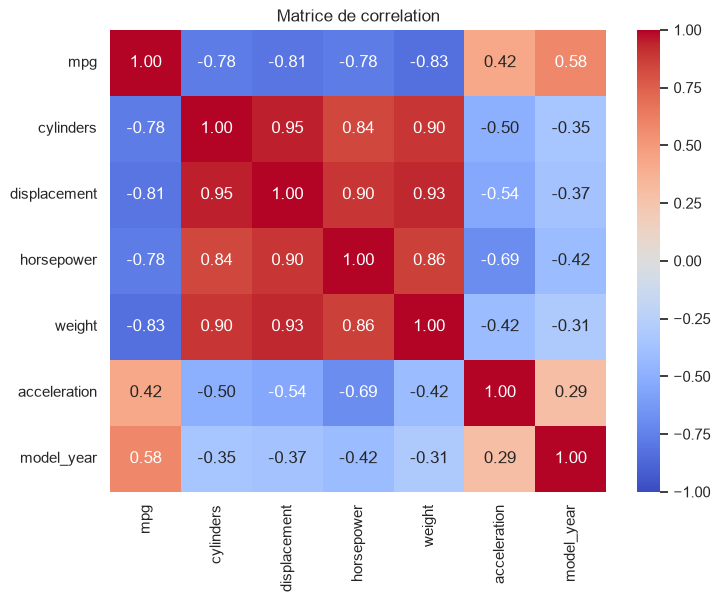

weight         -0.832244
displacement   -0.805127
horsepower     -0.778427
cylinders      -0.777618
acceleration    0.423329
model_year      0.580541
mpg             1.000000
Name: mpg, dtype: float64


In [11]:
# on garde seulement les colonnes numeriques utiles (sans name ni origin qui sont du texte)
cols_num = ["mpg", "cylinders"] + cols_continues
corr = df[cols_num].corr()

plt.figure(figsize=(8, 6))
# annot=True ecrit la valeur dans chaque case, cmap="coolwarm" : bleu = negatif, rouge = positif
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de correlation")
plt.show()

# la colonne mpg triee, pour voir directement les plus liees
print(corr["mpg"].sort_values())

## 2.5 Relation entre `mpg` et quelques variables

La corrélation ne voit que les relations **linéaires**. Un nuage de points (scatter plot)
permet de voir la forme réelle de la relation.

Si le nuage est courbé, un SVM linéaire sera limité, et un noyau (RBF) aura du sens.

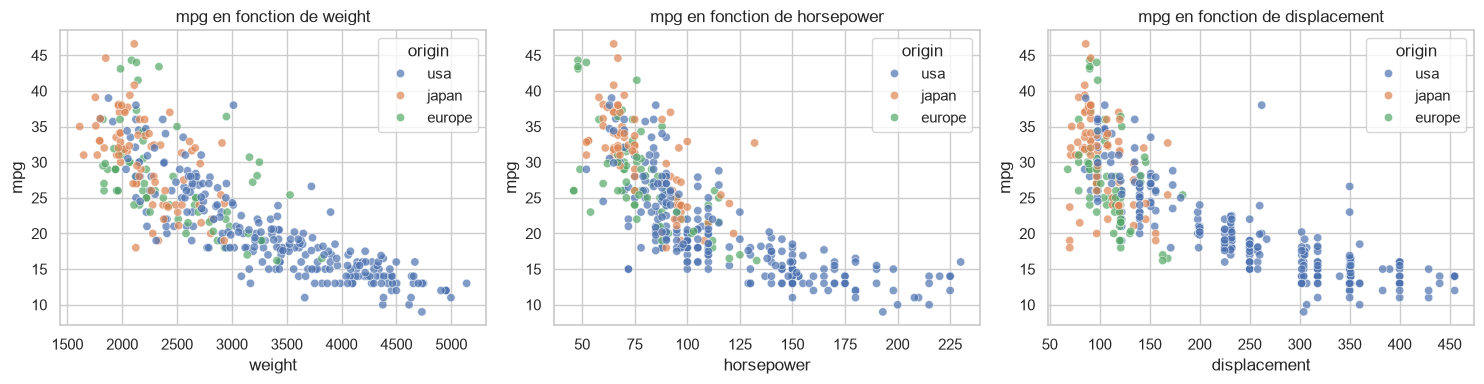

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# on colorie les points selon l'origine pour voir s'il y a des groupes
for ax, col in zip(axes, ["weight", "horsepower", "displacement"]):
    sns.scatterplot(data=df, x=col, y="mpg", hue="origin", alpha=0.7, ax=ax)
    ax.set_title("mpg en fonction de " + col)

plt.tight_layout()
plt.show()

## 2.6 Influence des variables catégorielles

Un **boxplot** (boîte à moustaches) résume la distribution de `mpg` pour chaque modalité :
- la ligne au milieu de la boîte = la **médiane** ;
- la boîte = les 50 % de valeurs centrales (du 1er au 3e quartile) ;
- les points isolés = des valeurs **extrêmes** (outliers) possibles.

Si les boîtes sont décalées entre elles, la variable influence `mpg`.

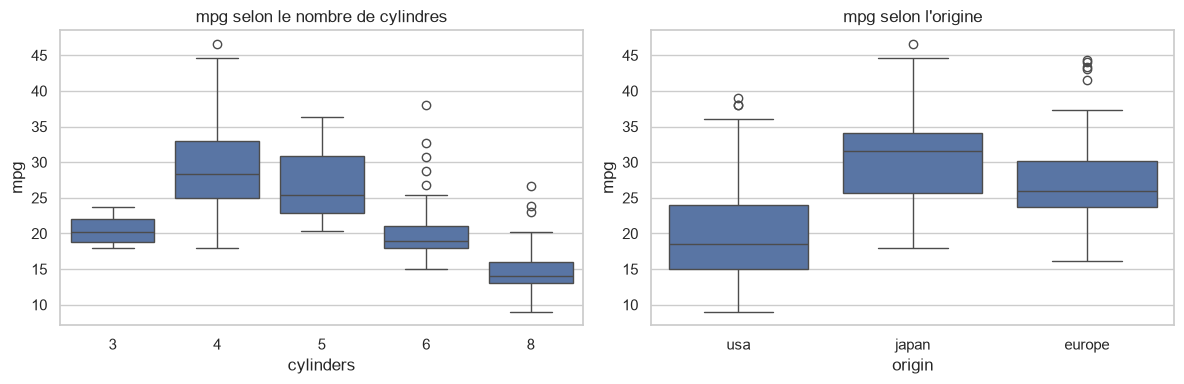

origin
europe    27.60
japan     30.45
usa       20.03
Name: mpg, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="cylinders", y="mpg", ax=axes[0]) # sert a voir la distribution de mpg selon le nombre de cylindres
axes[0].set_title("mpg selon le nombre de cylindres") 

sns.boxplot(data=df, x="origin", y="mpg", ax=axes[1]) # sert a voir la distribution de mpg selon l'origine
axes[1].set_title("mpg selon l'origine")

plt.tight_layout()
plt.show()

# moyenne de mpg par origine, pour avoir des chiffres
print(df.groupby("origin")["mpg"].mean().round(2))

# Partie 3 : Prétraitement des données

Un SVM ne comprend que des **nombres** et il est très sensible aux **échelles**.
On prépare donc les données en 4 étapes :

1. **Choisir les variables** : `mpg` est la cible (y), les autres colonnes sont les variables explicatives (X).
   On enlève `name` (du texte propre à chaque voiture, inutile pour prédire).
2. **Encoder `origin`** (usa / japan / europe) : c'est du texte, il faut le transformer en nombres.
3. **Découper en train / test** : le modèle apprend sur le train et on l'évalue sur le test,
   des données qu'il n'a jamais vues.
4. **Standardiser** les variables numériques, pour qu'elles aient toutes la même échelle.


## 3.1 Séparer X et y

- `y` = ce qu'on veut prédire (`mpg`)
- `X` = ce qu'on utilise pour prédire (les autres colonnes, sauf `name`)

In [14]:
# la cible
y = df["mpg"]

# les variables explicatives : on enleve la cible et le nom de la voiture
X = df.drop(columns=["mpg", "name"])

print("X :", X.shape)
print("y :", y.shape)
X.head()

X : (392, 7)
y : (392,)


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,8,307.0,130.0,3504,12.0,70,usa
1,8,350.0,165.0,3693,11.5,70,usa
2,8,318.0,150.0,3436,11.0,70,usa
3,8,304.0,150.0,3433,12.0,70,usa
4,8,302.0,140.0,3449,10.5,70,usa


## 3.2 Encodage de `origin` (one-hot)

`origin` vaut "usa", "japan" ou "europe". On ne peut pas écrire 1, 2, 3 : le modèle
croirait que "europe" est plus petit que "usa", ce qui n'a aucun sens.

On utilise le **one-hot encoding** : une colonne par modalité, qui vaut 1 si la voiture
est de cette origine et 0 sinon.

Exemple pour une voiture japonaise : `origin_japan = 1`, `origin_usa = 0`.

On utilise `drop_first=True` pour supprimer une colonne (ici `europe`). Elle est
**redondante** : si `japan = 0` et `usa = 0`, alors c'est forcément europe.
Garder les 3 colonnes créerait de la colinéarité parfaite.

**Et `cylinders` :** C'est une variable catégorielle dans le sujet, mais ses valeurs (3, 4, 5, 6, 8)
sont **ordonnées** et ont un vrai sens numérique (plus de cylindres = moteur plus gros).
On la garde donc comme un nombre, ce qui évite de créer 5 colonnes de plus pour seulement 392 lignes.

In [15]:
# get_dummies fait le one-hot encoding
# dtype=int pour avoir des 0/1 au lieu de True/False
X = pd.get_dummies(X, columns=["origin"], drop_first=True, dtype=int)

print("Colonnes de X :", list(X.columns))
X.head()

Colonnes de X : ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_japan', 'origin_usa']


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,8,307.0,130.0,3504,12.0,70,0,1
1,8,350.0,165.0,3693,11.5,70,0,1
2,8,318.0,150.0,3436,11.0,70,0,1
3,8,304.0,150.0,3433,12.0,70,0,1
4,8,302.0,140.0,3449,10.5,70,0,1


## 3.3 Découpage train / test

On sépare les données en deux :
- **train (80 %)** : le modèle apprend dessus ;
- **test (20 %)** : on le garde de côté pour évaluer le modèle sur des données jamais vues.

Si on évaluait sur les données d'entraînement, un modèle qui apprend par cœur aurait
un score parfait sans être capable de généraliser (c'est le **surapprentissage**, *overfitting*).

`random_state=42` fixe le tirage au sort pour retrouver le même découpage à chaque exécution.
On utilise `train_test_split` de scikit-learn : c'est juste un outil de découpage, pas un modèle,
donc ça ne contredit pas le "from scratch" demandé.

In [ ]:
from sklearn.model_selection import train_test_split # pour separer les donnees en train et test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train :", X_train.shape, "->", len(X_train), "voitures")
print("Test  :", X_test.shape, "->", len(X_test), "voitures")

Train : (313, 8) -> 313 voitures
Test  : (79, 8) -> 79 voitures


## 3.4 Standardisation

On a vu à l'étape 2 que `weight` vaut environ 3000 alors que `acceleration` vaut environ 15.
Un SVM calcule des distances et des produits scalaires : `weight` écraserait toutes les autres variables.

La **standardisation** ramène chaque variable à une moyenne de 0 et un écart-type de 1 :

$$x_{std} = \frac{x - \mu}{\sigma}$$

où $\mu$ est la moyenne et $\sigma$ l'écart-type de la colonne.

### Point crucial : éviter la fuite de données (*data leakage*)
On calcule $\mu$ et $\sigma$ **uniquement sur le train**, puis on applique **ces mêmes valeurs** au test.
Pourquoi ? Le test simule des données futures qu'on ne connaît pas encore. Si on calculait
la moyenne avec le test inclus, de l'information du test passerait dans l'entraînement
et le score serait trop optimiste.

On standardise les colonnes continues et `cylinders`. On laisse les colonnes one-hot (0/1) telles quelles,
elles sont déjà sur une petite échelle.

On le fait **à la main** avec numpy/pandas, puis on vérifie avec `StandardScaler` de scikit-learn.

In [17]:
# colonnes a standardiser (les colonnes 0/1 de origin restent telles quelles)
cols_a_standardiser = ["cylinders", "displacement", "horsepower",
                       "weight", "acceleration", "model_year"]

# moyenne et ecart-type calcules sur le TRAIN seulement
# ddof=0 : ecart-type "population", c'est ce que fait StandardScaler
moyennes = X_train[cols_a_standardiser].mean()
ecarts = X_train[cols_a_standardiser].std(ddof=0)

# on copie pour ne pas modifier les tableaux d'origine
X_train_s = X_train.copy()
X_test_s = X_test.copy()

# (x - moyenne) / ecart-type, avec les valeurs du train pour les deux
X_train_s[cols_a_standardiser] = (X_train[cols_a_standardiser] - moyennes) / ecarts
X_test_s[cols_a_standardiser] = (X_test[cols_a_standardiser] - moyennes) / ecarts

X_train_s.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
258,0.304862,0.284578,0.141429,0.754803,1.121759,0.494528,0,1
182,-0.873184,-0.535880,-0.329499,-0.493129,-0.228940,-0.057298,0,1
172,0.304862,-0.236655,-0.198685,-0.002530,-0.371118,-0.333211,0,1
63,1.482907,1.182255,1.187934,1.368052,-0.726565,-1.160950,0,1
340,-0.873184,-1.057113,-1.062052,-1.323099,0.304231,1.322266,0,1


## 3.5 Vérifications

Deux choses à contrôler :
1. Sur le **train**, chaque colonne standardisée doit avoir une moyenne ≈ 0 et un écart-type ≈ 1.
2. Sur le **test**, ce n'est **pas exactement** 0 et 1, et c'est normal : on a utilisé les
   paramètres du train, pas ceux du test.

On compare aussi avec `StandardScaler` : on doit retrouver exactement les mêmes valeurs.

In [ ]:
print("TRAIN - moyennes (doivent etre ~0) :")
print(X_train_s[cols_a_standardiser].mean().round(3)) # sert a verifier que la standardisation a bien ete faite
print()
print("TRAIN - ecarts-types (doivent etre ~1) :")
print(X_train_s[cols_a_standardiser].std(ddof=0).round(3)) 
print()
print("TEST - moyennes (proches de 0 mais pas exactement) :")
print(X_test_s[cols_a_standardiser].mean().round(3)) 

TRAIN - moyennes (doivent etre ~0) :
cylinders       0.0
displacement    0.0
horsepower     -0.0
weight          0.0
acceleration    0.0
model_year     -0.0
dtype: float64

TRAIN - ecarts-types (doivent etre ~1) :
cylinders       1.0
displacement    1.0
horsepower      1.0
weight          1.0
acceleration    1.0
model_year      1.0
dtype: float64

TEST - moyennes (proches de 0 mais pas exactement) :
cylinders      -0.031
displacement   -0.053
horsepower     -0.016
weight         -0.050
acceleration   -0.005
model_year     -0.312
dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler # pour standardiser les donnees

# meme operation avec scikit-learn
scaler = StandardScaler()
train_sk = scaler.fit_transform(X_train[cols_a_standardiser])  # fit = calcule moyenne/ecart sur le train
test_sk = scaler.transform(X_test[cols_a_standardiser])        # transform = applique, SANS recalculer

# allclose verifie que deux tableaux sont egaux (a une tolerance pres)
print("Train identique a StandardScaler :", np.allclose(X_train_s[cols_a_standardiser], train_sk))
print("Test identique a StandardScaler  :", np.allclose(X_test_s[cols_a_standardiser], test_sk))

Train identique a StandardScaler : True
Test identique a StandardScaler  : True


## 3.6 Conversion en tableaux numpy

Pour coder les SVM from scratch, on travaille avec des **tableaux numpy** (matrices),
pas des DataFrames pandas. On convertit avec `.values`.
On garde aussi les noms des colonnes pour s'y retrouver plus tard.

In [20]:
noms_features = list(X_train_s.columns)

# .values transforme le DataFrame en tableau numpy, astype(float) pour etre sur du type
X_train_np = X_train_s.values.astype(float)
X_test_np = X_test_s.values.astype(float)
y_train_np = y_train.values.astype(float)
y_test_np = y_test.values.astype(float)

print("X_train_np :", X_train_np.shape)
print("X_test_np  :", X_test_np.shape)
print("y_train_np :", y_train_np.shape)
print("y_test_np  :", y_test_np.shape)
print("Features :", noms_features)

X_train_np : (313, 8)
X_test_np  : (79, 8)
y_train_np : (313,)
y_test_np  : (79,)
Features : ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_japan', 'origin_usa']


# Partie 4 : Classification, discrétisation de la cible `mpg`

Pour faire de la classification, il faut une cible **catégorielle**.
On découpe donc `mpg` en 3 classes à l'aide de **2 seuils** $s_1 < s_2$ :

- `mpg < s1` : voiture qui consomme **beaucoup** (peu de miles par gallon)
- `s1 <= mpg < s2` : consommation **moyenne**
- `mpg >= s2` : voiture qui consomme **peu** (beaucoup de miles par gallon)

**NB** : mpg et consommation vont en sens **inverse**.
Un mpg élevé veut dire que la voiture fait beaucoup de miles avec peu d'essence,
donc une consommation **faible**. On code les classes dans l'ordre croissant de mpg :

| Classe | Valeur de mpg | Consommation |
|--------|---------------|--------------|
| 0      | basse         | élevée       |
| 1      | moyenne       | moyenne      |
| 2      | haute         | faible       |

**où placer les seuils ?** Ce choix change l'équilibre
des classes et donc la difficulté du problème. On compare 3 stratégies.

## 4.1 Les trois stratégies

**Stratégie A : intervalles de même largeur** (*equal-width*)
On coupe l'étendue [min, max] de mpg en 3 intervalles de même taille.
Simple, mais si les données sont étalées d'un côté,
les classes extrêmes seront très peu remplies.

**Stratégie B : quantiles** (*equal-frequency*)
On place les seuils aux percentiles 33 % et 67 % : chaque classe contient
environ **un tiers** des voitures. Les classes sont équilibrées par construction,
mais les seuils n'ont pas forcément de sens "métier".

**Stratégie C : seuils fixés par l'expérience** (*domain knowledge*)
On choisit des valeurs "parlantes", par exemple 20 et 30 mpg.
Ça a du sens pour un humain, mais rien ne garantit l'équilibre.

### Règle importante : les seuils se calculent sur le TRAIN uniquement
C'est le même raisonnement que pour la standardisation.
Les quantiles dépendent des données, donc si on les calcule avec le test,
on fait du *data leakage*. On calcule les seuils sur `y_train`,
puis on applique **les mêmes seuils** au test.

In [21]:
# strategie A : meme largeur
# on coupe l'etendue [min, max] du train en 3 morceaux egaux
mini, maxi = y_train_np.min(), y_train_np.max()
seuils_A = np.array([mini + (maxi - mini) / 3,
                     mini + 2 * (maxi - mini) / 3])

# strategie B : quantiles (33% et 67% des valeurs du train)
seuils_B = np.quantile(y_train_np, [1/3, 2/3])

# strategie C : seuils choisis a la main
seuils_C = np.array([20.0, 30.0])

seuils = {"A (meme largeur)": seuils_A,
          "B (quantiles)": seuils_B,
          "C (seuils fixes)": seuils_C}

for nom, s in seuils.items():
    print(nom, "-> seuils =", np.round(s, 2))

A (meme largeur) -> seuils = [21.53 34.07]
B (quantiles) -> seuils = [18.5 27. ]
C (seuils fixes) -> seuils = [20. 30.]


## 4.2 Appliquer les seuils

On utilise `np.digitize(valeurs, seuils)` : pour chaque valeur, elle renvoie
le numéro de l'intervalle dans lequel elle tombe.

Avec deux seuils $[s_1, s_2]$ :
- valeur $< s_1$ renvoie **0**
- $s_1 \le$ valeur $< s_2$ renvoie **1**
- valeur $\ge s_2$ renvoie **2**

C'est exactement le codage 0 / 1 / 2 défini plus haut.

In [22]:
# on regarde la repartition des classes sur le train pour chaque strategie
resultats = {}
for nom, s in seuils.items():
    classes = np.digitize(y_train_np, s)
    # bincount compte combien de fois chaque classe (0,1,2) apparait
    effectifs = np.bincount(classes, minlength=3)
    resultats[nom] = effectifs

# tableau recapitulatif : effectifs et pourcentages
tab = pd.DataFrame(resultats, index=["classe 0", "classe 1", "classe 2"]).T
tab_pct = (tab.div(tab.sum(axis=1), axis=0) * 100).round(1)

print("Effectifs :")
print(tab)
print()
print("Pourcentages :")
print(tab_pct)

Effectifs :
                  classe 0  classe 1  classe 2
A (meme largeur)       147       132        34
B (quantiles)          104        99       110
C (seuils fixes)       122       111        80

Pourcentages :
                  classe 0  classe 1  classe 2
A (meme largeur)      47.0      42.2      10.9
B (quantiles)         33.2      31.6      35.1
C (seuils fixes)      39.0      35.5      25.6


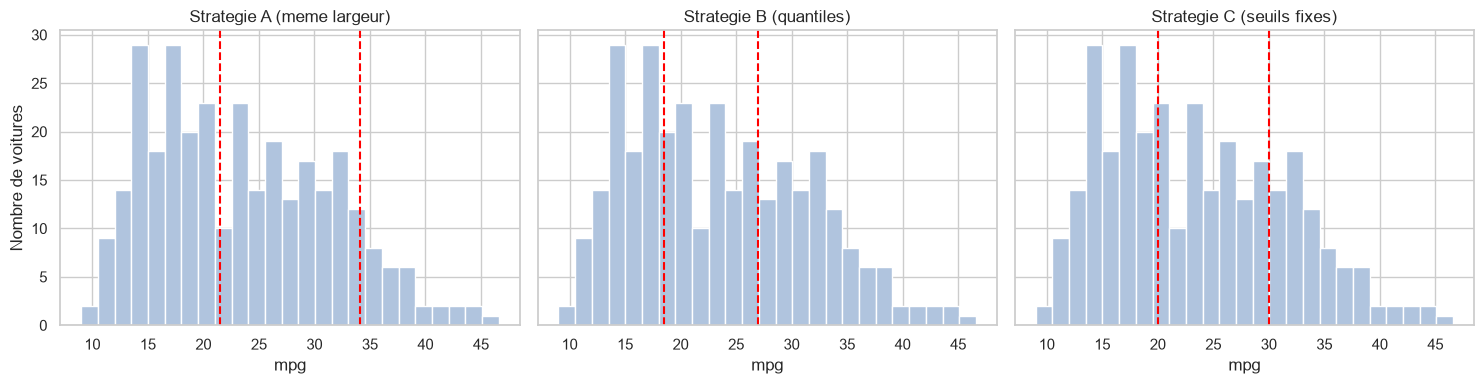

In [ ]:
# visualisation : histogramme de mpg (train) avec les seuils de chaque strategie
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
# on met les histogrammes sur la meme echelle pour mieux comparer
for ax, (nom, s) in zip(axes, seuils.items()):
    ax.hist(y_train_np, bins=25, color="lightsteelblue", edgecolor="white")
    for seuil in s: # on trace une ligne verticale pour chaque seuil
        ax.axvline(seuil, color="red", linestyle="--")
    ax.set_title("Strategie " + nom)
    ax.set_xlabel("mpg")

axes[0].set_ylabel("Nombre de voitures")
plt.tight_layout()
plt.show()

## 4.3 Impact du choix sur l'équilibre et la difficulté

**Équilibre des classes**
- Si une classe est très petite (par exemple 10 % des données), le SVM aura peu d'exemples
  pour la apprendre. Il aura tendance à la "sacrifier" et à prédire surtout les grandes classes.
- Dans ce cas, l'**accuracy** devient trompeuse : un modèle qui ignore la petite classe
  peut quand même avoir un bon score. On regarderait alors la **matrice de confusion**
  et le F1-score par classe.

**Difficulté du problème**
- Les erreurs arrivent surtout pour les voitures **proches d'un seuil** :
  une voiture à 19,9 mpg et une à 20,1 mpg sont presque identiques, mais pas dans la même classe.
- Un seuil placé dans une zone **dense** (beaucoup de voitures autour) crée beaucoup de cas ambigus,
  donc un problème plus difficile.
- Un seuil placé dans une zone **creuse** (peu de voitures) sépare mieux les classes,
  donc un problème plus facile, mais souvent au prix de classes déséquilibrées.

**Compromis** : équilibre des classes et facilité de séparation vont souvent en sens opposé.

## 4.4 Choix retenu

On retient la **stratégie B (quantiles)**, pour ces raisons :

1. Les trois classes sont **équilibrées**, donc l'accuracy est une métrique fiable
   et le SVM ne favorise pas une classe.
2. Elle s'adapte à la **forme** de la distribution, contrairement à la stratégie A.
3. Elle ne dépend pas d'un seuil arbitraire comme la stratégie C.

Son inconvénient est que les seuils (environ 19 et 26 mpg, à vérifier avec ton résultat)
sont des coupures "statistiques" : des voitures très proches de part et d'autre d'un seuil
seront dans des classes différentes. On en tient compte en lisant les erreurs du modèle.

In [24]:
# on garde les seuils de la strategie B (calcules sur le train)
s1, s2 = seuils_B
print("Seuils retenus : s1 =", round(s1, 2), " s2 =", round(s2, 2))

# creation des etiquettes de classe pour le train ET le test, avec les memes seuils
yc_train = np.digitize(y_train_np, seuils_B)
yc_test = np.digitize(y_test_np, seuils_B)

noms_classes = ["consommation elevee", "consommation moyenne", "consommation faible"]

print("\nTrain :", np.bincount(yc_train, minlength=3))
print("Test  :", np.bincount(yc_test, minlength=3))

Seuils retenus : s1 = 18.5  s2 = 27.0

Train : [104  99 110]
Test  : [23 35 21]


In [25]:
# verification : les mpg moyens de chaque classe doivent etre bien ordonnes
for k in range(3):
    mpg_classe = y_train_np[yc_train == k]
    print("classe", k, "(", noms_classes[k], ") : mpg de",
          round(mpg_classe.min(), 1), "a", round(mpg_classe.max(), 1),
          "| moyenne =", round(mpg_classe.mean(), 1))

classe 0 ( consommation elevee ) : mpg de 9.0 a 18.2 | moyenne = 15.2
classe 1 ( consommation moyenne ) : mpg de 18.5 a 26.6 | moyenne = 22.4
classe 2 ( consommation faible ) : mpg de 27.0 a 46.6 | moyenne = 32.7


## 4.5 Ce qui nous attend pour la suite

Un SVM est **naturellement binaire** : il sépare **2 classes** avec un hyperplan.
Or on en a 3. On utilisera la stratégie **un-contre-tous** (*One-vs-Rest*) :

- un SVM sépare "classe 0" contre "les autres" ;
- un SVM sépare "classe 1" contre "les autres" ;
- un SVM sépare "classe 2" contre "les autres" ;
- pour une nouvelle voiture, on prend la classe dont le SVM donne le **score le plus élevé**.

Pour chaque SVM binaire, les étiquettes doivent valoir **+1** (la classe visée) ou **-1** (les autres).

# Partie 5 : SVC linéaire from scratch

## 5.1 Le problème à résoudre

Pour **2 classes** notées $y_i \in \{-1, +1\}$, un SVM linéaire cherche un hyperplan
$w \cdot x + b = 0$. Le **score** d'une voiture est $f(x) = w \cdot x + b$ :
- score $> 0$ : on prédit **+1** ;
- score $< 0$ : on prédit **-1**.

### La marge d'un point
$$m_i = y_i \,(w \cdot x_i + b)$$

- $m_i > 0$ : le point est du **bon côté** de la frontière ;
- $m_i \ge 1$ : le point est du bon côté **et en dehors de la marge** (parfait) ;
- $0 < m_i < 1$ : bon côté mais **dans la marge** ;
- $m_i < 0$ : **mal classé**.

### La perte hinge
On pénalise un point seulement s'il est dans la marge ou mal classé :
$$\ell_i = \max(0,\; 1 - m_i)$$
Si $m_i \ge 1$ la perte vaut 0 : ces points n'influencent pas la solution.
Ceux qui ont $m_i \le 1$ sont les **vecteurs de support**.

### La fonction objectif (forme primale)
$$J(w,b) = \frac{\lambda}{2}\,\|w\|^2 \;+\; \frac{1}{n}\sum_{i=1}^{n} \max\bigl(0,\; 1 - y_i (w \cdot x_i + b)\bigr)$$

- Le terme $\frac{\lambda}{2}\|w\|^2$ **maximise la marge** (la largeur de la marge vaut $2/\|w\|$,
  donc minimiser $\|w\|$ revient à l'agrandir).
- Le terme hinge **pénalise les erreurs**.
- $\lambda$ règle le compromis. Il est lié au paramètre $C$ de scikit-learn par $C = \dfrac{1}{\lambda

## 5.3 Implémentation d'un SVM binaire

On écrit une **classe** `SVMLineaire` avec trois méthodes :
- `fit(X, y)` : entraîne le modèle (la descente de gradient) ;
- `score(X)` : calcule $w \cdot x + b$ pour chaque ligne ;
- `predict(X)` : renvoie +1 ou -1 selon le signe du score.

On garde aussi l'historique de la fonction objectif `J` à chaque itération, pour
vérifier visuellement que la descente fonctionne (la courbe doit **descendre**).

In [26]:
class SVMLineaire:
    """SVM lineaire binaire, entraine par descente de gradient sur la perte hinge."""

    def __init__(self, lam=0.01, lr=0.1, n_iter=2000):
        self.lam = lam          # force de la regularisation (lie a C par C = 1/(lam*n))
        self.lr = lr            # pas d'apprentissage de depart
        self.n_iter = n_iter    # nombre d'iterations
        self.w = None
        self.b = 0.0
        self.historique = []    # valeur de J a chaque iteration

    def fit(self, X, y):
        # y doit contenir des -1 et des +1
        n, d = X.shape
        self.w = np.zeros(d)    # on part de zero
        self.b = 0.0
        self.historique = []

        for t in range(self.n_iter):
            # 1) scores et marges de tous les points
            scores = X @ self.w + self.b
            marges = y * scores

            # 2) points qui violent la marge (m < 1)
            viol = marges < 1

            # 3) valeur de la fonction objectif J (juste pour suivre l'apprentissage)
            hinge = np.maximum(0, 1 - marges)
            J = 0.5 * self.lam * np.dot(self.w, self.w) + hinge.mean()
            self.historique.append(J)

            # 4) sous-gradients (seuls les points qui violent la marge comptent)
            grad_w = self.lam * self.w - (X[viol].T @ y[viol]) / n
            grad_b = -y[viol].sum() / n

            # 5) pas qui diminue avec le temps
            lr_t = self.lr / (1 + 0.01 * t)

            # 6) mise a jour
            self.w = self.w - lr_t * grad_w
            self.b = self.b - lr_t * grad_b

        return self

    def score(self, X):
        # w.x + b pour chaque ligne de X
        return X @ self.w + self.b

    def predict(self, X):
        # +1 si le score est positif, -1 sinon
        return np.where(self.score(X) >= 0, 1, -1)

    def n_support(self, X, y, tol=1e-6):
        # vecteurs de support = points avec marge <= 1
        marges = y * self.score(X)
        return int(np.sum(marges <= 1 + tol))

## 5.4 Test sur un problème binaire

Avant de passer aux 3 classes, on vérifie que le modèle marche sur un cas simple :
**classe 0 contre les autres** (voitures qui consomment beaucoup contre le reste).

On transforme les étiquettes en $+1$ (classe 0) et $-1$ (les autres) avec `np.where`.
On trace ensuite la courbe de $J$ : si elle **descend puis se stabilise**, la descente de gradient fonctionne.

Accuracy train : 0.933
Accuracy test  : 0.899
Vecteurs de support : 68 sur 313


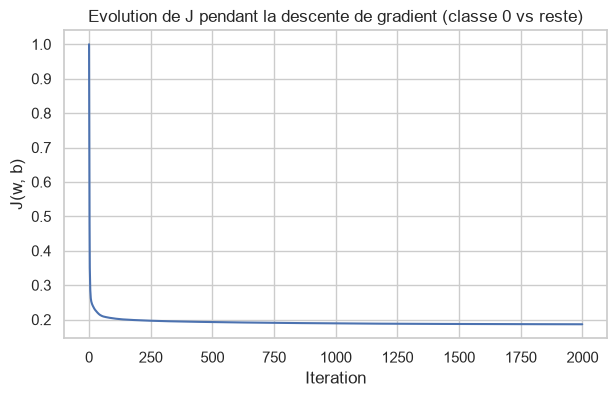

In [27]:
# classe 0 contre les autres : +1 pour la classe 0, -1 pour le reste
y_bin_train = np.where(yc_train == 0, 1, -1)
y_bin_test = np.where(yc_test == 0, 1, -1)

# entrainement
svm0 = SVMLineaire(lam=0.01, lr=0.1, n_iter=2000)
svm0.fit(X_train_np, y_bin_train)

# precision (accuracy) = proportion de bonnes predictions
acc_train = np.mean(svm0.predict(X_train_np) == y_bin_train)
acc_test = np.mean(svm0.predict(X_test_np) == y_bin_test)
print("Accuracy train :", round(acc_train, 3))
print("Accuracy test  :", round(acc_test, 3))
print("Vecteurs de support :", svm0.n_support(X_train_np, y_bin_train), "sur", len(X_train_np))

# courbe de la fonction objectif
plt.figure(figsize=(7, 4))
plt.plot(svm0.historique)
plt.title("Evolution de J pendant la descente de gradient (classe 0 vs reste)")
plt.xlabel("Iteration")
plt.ylabel("J(w, b)")
plt.show()

## 5.5 Extension à 3 classes : One-vs-Rest

On entraîne **3 SVM binaires**, un par classe :
- SVM 0 : classe 0 (+1) contre les autres (-1)
- SVM 1 : classe 1 (+1) contre les autres (-1)
- SVM 2 : classe 2 (+1) contre les autres (-1)

Pour une nouvelle voiture, on calcule les 3 scores et on prédit la classe
dont le score est **le plus grand** (`np.argmax`). Le score est une sorte de
"confiance" : plus il est grand, plus la voiture est loin de la frontière du bon côté.

In [28]:
class SVCLineaireOvR:
    """SVC lineaire multi-classes avec la strategie un-contre-tous."""

    def __init__(self, lam=0.01, lr=0.1, n_iter=2000):
        self.lam = lam
        self.lr = lr
        self.n_iter = n_iter
        self.modeles = []     # un SVM binaire par classe

    def fit(self, X, y):
        self.classes = np.unique(y)     # [0, 1, 2]
        self.modeles = []
        for k in self.classes:
            # +1 pour la classe k, -1 pour toutes les autres
            y_bin = np.where(y == k, 1, -1)
            svm = SVMLineaire(self.lam, self.lr, self.n_iter)
            svm.fit(X, y_bin)
            self.modeles.append(svm)
        return self

    def scores(self, X):
        # matrice (n_exemples, n_classes) : une colonne de scores par SVM
        return np.column_stack([m.score(X) for m in self.modeles])

    def predict(self, X):
        # classe avec le score le plus grand
        return self.classes[np.argmax(self.scores(X), axis=1)]

In [29]:
# entrainement du SVC lineaire from scratch (3 classes)
svc_perso = SVCLineaireOvR(lam=0.01, lr=0.1, n_iter=2000)
svc_perso.fit(X_train_np, yc_train)

pred_train_perso = svc_perso.predict(X_train_np)
pred_test_perso = svc_perso.predict(X_test_np)

print("SVC lineaire from scratch")
print("Accuracy train :", round(np.mean(pred_train_perso == yc_train), 3))
print("Accuracy test  :", round(np.mean(pred_test_perso == yc_test), 3))

SVC lineaire from scratch
Accuracy train : 0.741
Accuracy test  : 0.544


## 5.6 Comparaison avec scikit-learn

On entraîne le même modèle avec scikit-learn :
- `SVC(kernel="linear")` : SVM linéaire. Par défaut il gère le multi-classes en **One-vs-One**,
  donc on l'enveloppe dans `OneVsRestClassifier` pour avoir **la même stratégie** que nous.
- Pour avoir le même problème d'optimisation, on utilise $C = \dfrac{1}{\lambda n}$.

Les résultats ne seront pas identiques à 100 %, et c'est normal :
- scikit-learn résout le **problème dual** de façon exacte (solveur libsvm) ;
- nous, on fait une **descente de gradient** qui s'arrête après un nombre fixé d'itérations.

On s'attend à une accuracy **très proche** et à un fort pourcentage de prédictions identiques.

In [ ]:
from sklearn.svm import SVC # pour le SVC lineaire de scikit-learn
from sklearn.multiclass import OneVsRestClassifier # pour la strategie un-contre-tous

# C equivalent a notre lambda
n_train = len(X_train_np)
C_equiv = 1 / (0.01 * n_train)
print("C equivalent :", round(C_equiv, 3))
# entrainement du SVC lineaire de scikit-learn (3 classes)
svc_sk = OneVsRestClassifier(SVC(kernel="linear", C=C_equiv))
svc_sk.fit(X_train_np, yc_train)
# prediction sur le train et le test
pred_train_sk = svc_sk.predict(X_train_np)
pred_test_sk = svc_sk.predict(X_test_np)

print("SVC lineaire scikit-learn")
print("Accuracy train :", round(np.mean(pred_train_sk == yc_train), 3))
print("Accuracy test  :", round(np.mean(pred_test_sk == yc_test), 3))

# part de predictions identiques entre les deux modeles (sur le test)
print("\nPredictions identiques (test) :", round(np.mean(pred_test_perso == pred_test_sk) * 100, 1), "%")

C equivalent : 0.319
SVC lineaire scikit-learn
Accuracy train : 0.77
Accuracy test  : 0.582

Predictions identiques (test) : 94.9 %


## 5.7 Comparer les hyperplans et les erreurs

Deux vérifications supplémentaires :

1. **Les coefficients $w$** : on compare, pour la classe 0 contre le reste, notre $w$
   à celui de scikit-learn (attribut `coef_`). Ils doivent avoir les **mêmes signes** et des valeurs proches.
2. **La matrice de confusion** : les lignes sont les vraies classes, les colonnes les classes prédites.
   La diagonale = bonnes prédictions. On s'attend à ce que les erreurs soient entre classes
   **voisines** (0 et 1, ou 1 et 2), rarement entre 0 et 2.

        feature  w from scratch  w scikit-learn
0     cylinders           0.416           0.197
1  displacement           0.628           0.675
2    horsepower           0.324           0.348
3        weight           0.779           1.093
4  acceleration           0.085           0.069
5    model_year          -0.840          -1.034
6  origin_japan          -0.197          -0.319
7    origin_usa          -0.169           0.122


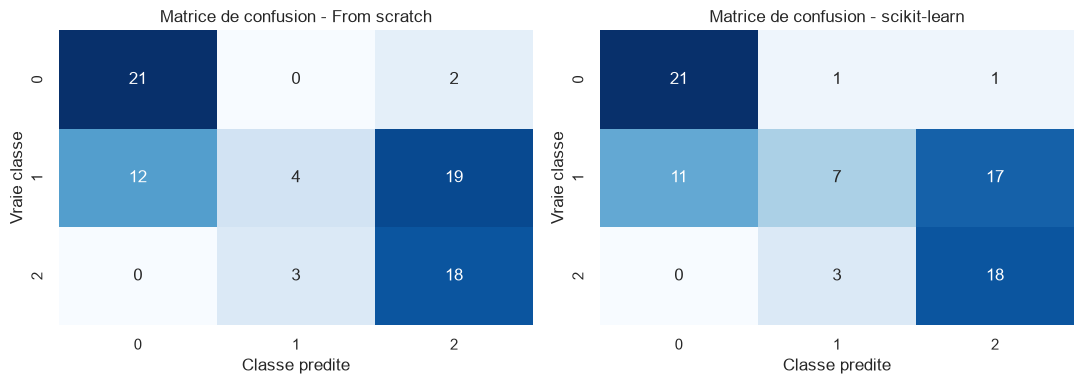

In [ ]:
# 1) comparaison des coefficients (classe 0 contre le reste)
w_perso = svc_perso.modeles[0].
w_sk = svc_sk.estimators_[0].coef_.ravel()

comparaison_w = pd.DataFrame({"feature": noms_features,
                              "w from scratch": np.round(w_perso, 3),
                              "w scikit-learn": np.round(w_sk, 3)})
print(comparaison_w)

# 2) matrice de confusion faite a la main
def matrice_confusion(y_vrai, y_pred, n_classes=3):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for vrai, pred in zip(y_vrai, y_pred):
        M[vrai, pred] += 1       # ligne = vraie classe, colonne = classe predite
    return M
# 3) affichage des matrices de confusion
M_perso = matrice_confusion(yc_test, pred_test_perso)
M_sk = matrice_confusion(yc_test, pred_test_sk)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, M, titre in zip(axes, [M_perso, M_sk], ["From scratch", "scikit-learn"]):
    sns.heatmap(M, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[0, 1, 2], yticklabels=[0, 1, 2])
    ax.set_title("Matrice de confusion - " + titre)
    ax.set_xlabel("Classe predite")
    ax.set_ylabel("Vraie classe")
plt.tight_layout()
plt.show()

# Partie 6 : SVC à noyau (RBF) from scratch

## 6.1 Pourquoi un noyau ?

À l'étape 2, on a vu que la relation entre `mpg` et `weight` ou `horsepower` est **courbe**.
Un SVM linéaire ne sait tracer que des frontières **droites**, donc il est limité.

**Idée** : projeter les données dans un espace de plus grande dimension où elles deviennent
séparables par un hyperplan. Une droite dans cet espace correspond à une **courbe** dans l'espace d'origine.

**Astuce du noyau** (*kernel trick*) : on n'a jamais besoin de calculer cette projection.
Il suffit de savoir calculer le **produit scalaire** dans l'espace projeté, via une fonction
$K(x, x')$ appelée **noyau**. Un noyau mesure la **similarité** entre deux points.

## 6.2 Le noyau RBF (gaussien)

$$K(x, x') = \exp\bigl(-\gamma\,\|x - x'\|^2\bigr)$$

- Deux points **identiques** : $\|x-x'\|=0$ donc $K = 1$ (similarité maximale).
- Deux points **très éloignés** : $K \to 0$ (aucune similarité).
- $\gamma > 0$ règle la **portée** de l'influence d'un point :
  - **$\gamma$ grand** : influence très locale, frontière très "tordue", risque de **surapprentissage** ;
  - **$\gamma$ petit** : influence large, frontière lisse, risque de **sous-apprentissage** (proche du linéaire).

## 6.3 Comment on le met en œuvre ici

On utilise le **théorème du représentant** : la fonction de décision s'écrit comme une
combinaison des points d'entraînement,

$$f(x) = \sum_{j=1}^{n} \alpha_j \, K(x_j, x) + b$$

Au lieu d'apprendre $w$ (qui vit dans l'espace projeté, qu'on ne manipule jamais), on apprend
les **coefficients $\alpha_j$**, un par point d'entraînement. Avec la matrice de Gram
$K_{ij} = K(x_i, x_j)$ (taille $n \times n$), les scores de tous les points s'écrivent d'un coup :

$$f = K\alpha + b$$

L'objectif garde la même forme qu'à l'étape 5 (marge + hinge) :

$$J(\alpha, b) = \frac{\lambda}{2}\,\alpha^\top K \alpha + \frac{1}{n}\sum_{i=1}^{n}\max\bigl(0,\,1 - y_i f_i\bigr)$$

Le terme $\alpha^\top K\alpha$ vaut $\|w\|^2$ dans l'espace projeté : c'est toujours le terme "grande marge".

Le sous-gradient (même logique qu'avant : seuls les points avec $m_i<1$ comptent) donne :

$$\nabla_\alpha J = K\Bigl(\lambda\alpha - \tfrac{1}{n}\,(y \odot v)\Bigr)
\qquad
\nabla_b J = -\tfrac{1}{n}\sum_i y_i v_i$$

où $v_i = 1$ si $m_i < 1$ (le point viole la marge) et $0$ sinon, et $\odot$ est le produit terme à terme.

**Les vecteurs de support** sont toujours les points avec $m_i \le 1$. Leur nombre est
une bonne mesure de la

## 6.4 Le noyau RBF en numpy

Pour calculer $\|x - x'\|^2$ pour **toutes les paires** de points sans boucle (trop lent),
on utilise l'identité :

$$\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2\,x\cdot x'$$

Ça permet de calculer toute la matrice d'un seul coup avec un produit matriciel.

**Choix de $\gamma$** : on prend la même règle que scikit-learn (`gamma="scale"`) :
$$\gamma = \frac{1}{d \cdot \mathrm{Var}(X)}$$
où $d$ est le nombre de variables et $\mathrm{Var}(X)$ la variance de **toutes** les valeurs de $X_{train}$.
On utilise **la même valeur** pour notre modèle et pour scikit-learn, pour que la comparaison soit équitable.

In [32]:
def noyau_rbf(A, B, gamma):
    """Matrice K[i, j] = exp(-gamma * ||A_i - B_j||^2)."""
    # carres des normes de chaque ligne
    normes_A = np.sum(A ** 2, axis=1).reshape(-1, 1)   # colonne
    normes_B = np.sum(B ** 2, axis=1).reshape(1, -1)   # ligne
    # ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a.b  (le broadcasting fait toutes les paires)
    dist2 = normes_A + normes_B - 2 * (A @ B.T)
    # des erreurs d'arrondi peuvent donner de tout petits negatifs, on les remet a 0
    dist2 = np.maximum(dist2, 0)
    return np.exp(-gamma * dist2)


# gamma choisi avec la meme formule que scikit-learn ("scale")
d = X_train_np.shape[1]
gamma = 1 / (d * X_train_np.var())
print("gamma =", round(gamma, 4))

# petite verification : un point est identique a lui meme, donc K(x, x) = 1
K_test_diag = noyau_rbf(X_train_np[:5], X_train_np[:5], gamma)
print("\nExtrait de la matrice de Gram (5 premiers points) :")
print(np.round(K_test_diag, 3))

gamma = 0.148

Extrait de la matrice de Gram (5 premiers points) :
[[1.    0.413 0.564 0.234 0.218]
 [0.413 1.    0.763 0.097 0.58 ]
 [0.564 0.763 1.    0.305 0.318]
 [0.234 0.097 0.305 1.    0.012]
 [0.218 0.58  0.318 0.012 1.   ]]


## 6.5 Implémentation du SVM à noyau (binaire)

La classe est construite comme `SVMLineaire`, avec trois différences :
- `fit` calcule d'abord la matrice de Gram $K$ sur le train, puis apprend $\alpha$ et $b$ ;
- on garde `X_train` en mémoire, car la prédiction en a besoin : $f(x)=\sum_j \alpha_j K(x_j,x)+b$ ;
- `score` calcule la similarité entre les **nouveaux** points et les points du **train**.

On garde l'historique de $J$ pour vérifier que la descente fonctionne.

In [33]:
class SVMNoyauRBF:
    """SVM binaire a noyau RBF, entraine par descente de gradient (forme avec alpha)."""

    def __init__(self, gamma, lam=0.01, lr=0.1, n_iter=3000):
        self.gamma = gamma
        self.lam = lam
        self.lr = lr
        self.n_iter = n_iter
        self.alpha = None
        self.b = 0.0
        self.X_train = None
        self.historique = []

    def fit(self, X, y):
        # y doit contenir des -1 et des +1
        n = X.shape[0]
        self.X_train = X                       # a garder pour predire plus tard
        K = noyau_rbf(X, X, self.gamma)        # matrice de Gram (n x n)

        self.alpha = np.zeros(n)
        self.b = 0.0
        self.historique = []

        for t in range(self.n_iter):
            # 1) scores et marges de tous les points
            f = K @ self.alpha + self.b
            marges = y * f

            # 2) v = 1 pour les points qui violent la marge, 0 sinon
            v = (marges < 1).astype(float)

            # 3) fonction objectif (pour suivre l'apprentissage)
            hinge = np.maximum(0, 1 - marges)
            J = 0.5 * self.lam * (self.alpha @ K @ self.alpha) + hinge.mean()
            self.historique.append(J)

            # 4) sous-gradients
            grad_alpha = K @ (self.lam * self.alpha - (y * v) / n)
            grad_b = -np.sum(y * v) / n

            # 5) pas qui diminue avec le temps
            lr_t = self.lr / (1 + 0.01 * t)

            # 6) mise a jour
            self.alpha = self.alpha - lr_t * grad_alpha
            self.b = self.b - lr_t * grad_b

        return self

    def score(self, X):
        # similarite entre les nouveaux points et les points du train
        K_new = noyau_rbf(X, self.X_train, self.gamma)
        return K_new @ self.alpha + self.b

    def predict(self, X):
        return np.where(self.score(X) >= 0, 1, -1)

    def n_support(self, y, tol=1e-6):
        # vecteurs de support = points du train avec marge <= 1
        marges = y * self.score(self.X_train)
        return int(np.sum(marges <= 1 + tol))

## 6.6 Test binaire : classe 0 contre les autres

Pour comparer directement avec le modèle linéaire :
on regarde la courbe de $J$ (elle doit descendre) et les accuracy.

SVM RBF (classe 0 vs reste)
Accuracy train : 0.939
Accuracy test  : 0.899
Vecteurs de support : 90 sur 313


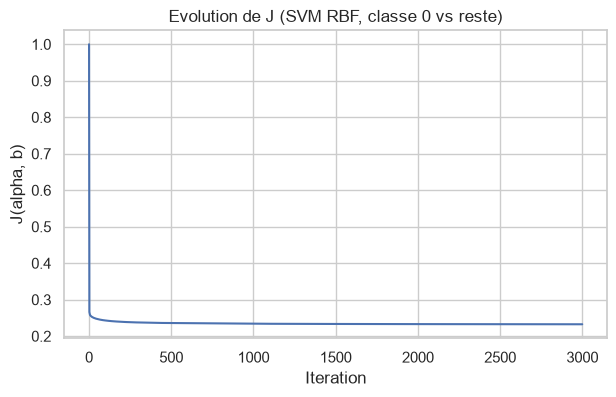

In [34]:
# memes etiquettes binaires qu'a l'etape 5 (classe 0 contre le reste)
svm0_rbf = SVMNoyauRBF(gamma=gamma, lam=0.01, lr=0.1, n_iter=3000)
svm0_rbf.fit(X_train_np, y_bin_train)

print("SVM RBF (classe 0 vs reste)")
print("Accuracy train :", round(np.mean(svm0_rbf.predict(X_train_np) == y_bin_train), 3))
print("Accuracy test  :", round(np.mean(svm0_rbf.predict(X_test_np) == y_bin_test), 3))
print("Vecteurs de support :", svm0_rbf.n_support(y_bin_train), "sur", len(X_train_np))

plt.figure(figsize=(7, 4))
plt.plot(svm0_rbf.historique)
plt.title("Evolution de J (SVM RBF, classe 0 vs reste)")
plt.xlabel("Iteration")
plt.ylabel("J(alpha, b)")
plt.show()

## 6.7 Extension à 3 classes (One-vs-Rest)

Exactement comme à l'étape 5 : un SVM RBF par classe (+1 pour la classe visée, -1 pour les autres),
puis on prédit la classe de **score maximal**.

In [ ]:
class SVCRBFOvR:
    """SVC a noyau RBF multi-classes (un-contre-tous)."""
# pour chaque classe k, on entraine un SVM binaire avec +1 pour la classe k et -1 pour les autres
    def __init__(self, gamma, lam=0.01, lr=0.1, n_iter=3000):
        self.gamma = gamma
        self.lam = lam
        self.lr = lr
        self.n_iter = n_iter
        self.modeles = []

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.modeles = []
        for k in self.classes:
            y_bin = np.where(y == k, 1, -1)
            svm = SVMNoyauRBF(self.gamma, self.lam, self.lr, self.n_iter)
            svm.fit(X, y_bin)
            self.modeles.append(svm)
        return self

    def scores(self, X):
        return np.column_stack([m.score(X) for m in self.modeles])

    def predict(self, X):
        return self.classes[np.argmax(self.scores(X), axis=1)]


# entrainement
svc_rbf_perso = SVCRBFOvR(gamma=gamma, lam=0.01, lr=0.1, n_iter=3000)
svc_rbf_perso.fit(X_train_np, yc_train)

pred_train_rbf = svc_rbf_perso.predict(X_train_np)
pred_test_rbf = svc_rbf_perso.predict(X_test_np)

print("SVC RBF from scratch")
print("Accuracy train :", round(np.mean(pred_train_rbf == yc_train), 3))
print("Accuracy test  :", round(np.mean(pred_test_rbf == yc_test), 3))

SVC RBF from scratch
Accuracy train : 0.831
Accuracy test  : 0.81


## 6.8 Comparaison avec scikit-learn

On entraîne `SVC(kernel="rbf")` avec :
- le **même $\gamma$** ;
- le **même $C = 1/(\lambda n)$** ;
- `OneVsRestClassifier`, pour avoir la même stratégie multi-classes.

Comme à l'étape 5, on s'attend à des résultats **proches mais pas identiques** :
scikit-learn résout le problème dual exactement, nous faisons une descente de gradient approchée.

In [ ]:
C_equiv = 1 / (0.01 * len(X_train_np)) # C equivalent a notre lambda
# entrainement du SVC RBF de scikit-learn (3 classes)
svc_rbf_sk = OneVsRestClassifier(SVC(kernel="rbf", C=C_equiv, gamma=gamma))
svc_rbf_sk.fit(X_train_np, yc_train)
# prediction sur le train et le test
pred_train_rbf_sk = svc_rbf_sk.predict(X_train_np)
pred_test_rbf_sk = svc_rbf_sk.predict(X_test_np)

print("SVC RBF scikit-learn")
print("Accuracy train :", round(np.mean(pred_train_rbf_sk == yc_train), 3))
print("Accuracy test  :", round(np.mean(pred_test_rbf_sk == yc_test), 3))
print("\nPredictions identiques (test) :",
      round(np.mean(pred_test_rbf == pred_test_rbf_sk) * 100, 1), "%")

# nombre de vecteurs de support de la classe 0 vs reste, des deux cotes
n_sv_sk = svc_rbf_sk.estimators_[0].n_support_.sum()
print("\nVecteurs de support (classe 0 vs reste) :")
print("  from scratch :", svc_rbf_perso.modeles[0].n_support(np.where(yc_train == 0, 1, -1)))
print("  scikit-learn :", n_sv_sk)

SVC RBF scikit-learn
Accuracy train : 0.853
Accuracy test  : 0.797

Predictions identiques (test) : 98.7 %

Vecteurs de support (classe 0 vs reste) :
  from scratch : 90
  scikit-learn : 95


## 6.9 Linéaire contre RBF : tableau récapitulatif

On rassemble tous les modèles de l'étape 5 et 6 dans un seul tableau.

In [ ]:
recap = pd.DataFrame({ # pour faire un joli tableau recapitulatif
    "Modele": ["Lineaire from scratch", "Lineaire scikit-learn",
               "RBF from scratch", "RBF scikit-learn"],
    "Acc. train": [np.mean(pred_train_perso == yc_train), # pourcentage de bonnes predictions sur le train
                   np.mean(pred_train_sk == yc_train),
                   np.mean(pred_train_rbf == yc_train),
                   np.mean(pred_train_rbf_sk == yc_train)],
    "Acc. test": [np.mean(pred_test_perso == yc_test), # pourcentage de bonnes predictions sur le test
                  np.mean(pred_test_sk == yc_test),
                  np.mean(pred_test_rbf == yc_test),
                  np.mean(pred_test_rbf_sk == yc_test)],
})
print(recap.round(3).to_string(index=False))

               Modele  Acc. train  Acc. test
Lineaire from scratch       0.741      0.544
Lineaire scikit-learn       0.770      0.582
     RBF from scratch       0.831      0.810
     RBF scikit-learn       0.853      0.797


## 6.10 Influence de $\gamma$ (pour comprendre le noyau)

On refait tourner notre SVC RBF avec plusieurs valeurs de $\gamma$ et on regarde l'accuracy
sur le train **et** sur le test :

- $\gamma$ trop petit : le modèle est trop lisse, mauvais partout (sous-apprentissage) ;
- $\gamma$ trop grand : très bon sur le train, mauvais sur le test (**surapprentissage**).

L'écart entre train et test est le signe à surveiller.

 gamma  Acc. train  Acc. test
 0.002       0.674      0.544
 0.015       0.681      0.532
 0.148       0.831      0.810
 1.480       0.872      0.759
14.799       0.997      0.494


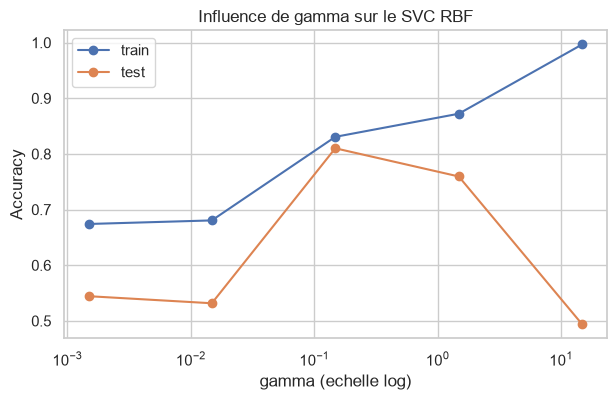

In [ ]:
# on teste le gamma de reference multiplie ou divise par 10 et 100
facteurs = [0.01, 0.1, 1, 10, 100]
lignes = []
# on fait tourner le modele pour chaque gamma
for f in facteurs:
    g = gamma * f
    modele = SVCRBFOvR(gamma=g, lam=0.01, lr=0.1, n_iter=3000)
    modele.fit(X_train_np, yc_train)
    lignes.append([round(g, 4),
                   np.mean(modele.predict(X_train_np) == yc_train),
                   np.mean(modele.predict(X_test_np) == yc_test)])
# on met les resultats dans un DataFrame pour un affichage plus joli
etude_gamma = pd.DataFrame(lignes, columns=["gamma", "Acc. train", "Acc. test"])
print(etude_gamma.round(3).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.semilogx(etude_gamma["gamma"], etude_gamma["Acc. train"], "o-", label="train")
plt.semilogx(etude_gamma["gamma"], etude_gamma["Acc. test"], "o-", label="test")
plt.xlabel("gamma (echelle log)")
plt.ylabel("Accuracy")
plt.title("Influence de gamma sur le SVC RBF")
plt.legend()
plt.show()

La perte n'est pas dérivable en $|r_i| = \varepsilon$ ni en $r_i = 0$, on utilise un sous-gradient. Seuls les points **hors du tube** ($|r_i| > \varepsilon$) contribuent :

$$\nabla_w J = \lambda w - \frac{1}{n}\sum_{\{i \mid |r_i| > \varepsilon\}} \text{sign}(r_i) x_i$$

## 7.6 Préparer la cible : standardiser `y`

Contrairement à la classification (où $y=\pm1$), ici $y$ = `mpg` vaut entre environ 9 et 46,
avec une moyenne autour de 23. Deux problèmes pour la descente de gradient :

1. Le biais $b$ doit atteindre environ 23, alors que ses mises à jour sont petites : convergence lente.
2. Le paramètre $\varepsilon$ dépendrait de l'unité de `mpg`, donc moins facile à interpréter.

**Solution** : on standardise aussi la cible, avec la **moyenne et l'écart-type du train uniquement**
(même règle anti-fuite qu'à l'étape 3) :

$$y_s = \frac{y - \mu_y}{\sigma_y}$$

On entraîne sur $y_s$, puis on **repasse en mpg** pour calculer les erreurs :
$\hat y = \hat y_s \cdot \sigma_y + \mu_y$.

Désormais, $\varepsilon$ s'exprime en **écarts-types de mpg**. Par exemple $\varepsilon=0{,}1$
correspond à environ $0{,}1\times\sigma_y$ mpg.

In [39]:
# moyenne et ecart-type de la cible, calcules sur le TRAIN seulement
mu_y = y_train_np.mean()
sd_y = y_train_np.std()      # ddof=0 par defaut dans numpy, comme pour X

# cible standardisee
ys_train = (y_train_np - mu_y) / sd_y
ys_test = (y_test_np - mu_y) / sd_y

print("mu_y =", round(mu_y, 2), "| sd_y =", round(sd_y, 2))
print("moyenne de ys_train :", round(ys_train.mean(), 3), "(doit etre ~0)")
print("ecart-type de ys_train :", round(ys_train.std(), 3), "(doit etre ~1)")

# pour info : epsilon = 0.1 en unites standardisees, ca fait combien de mpg ?
print("\nepsilon = 0.1  <=>", round(0.1 * sd_y, 2), "mpg")

mu_y = 23.6 | sd_y = 7.94
moyenne de ys_train : 0.0 (doit etre ~0)
ecart-type de ys_train : 1.0 (doit etre ~1)

epsilon = 0.1  <=> 0.79 mpg


## 7.7 Implémentation du SVR linéaire

La classe ressemble à `SVMLineaire` (étape 5). Les différences :

- on calcule le **résidu** `r = y - (X @ w + b)` au lieu de la marge ;
- les points actifs sont ceux **hors du tube** : `np.abs(r) > epsilon` ;
- le gradient utilise `np.sign(r)` au lieu de `y` ;
- `n_support` compte les points **sur le bord ou hors du tube**.

Pour les vecteurs de support, la descente de gradient n'arrive presque jamais *exactement* sur le bord
du tube. On accepte donc une petite tolérance. Le nombre trouvé sera **approché**,
contrairement à scikit-learn qui le calcule exactement.

In [ ]:
class SVRLineaire:
    """SVR lineaire (perte epsilon-insensible), entraine par descente de gradient."""
# pour chaque point, si la prediction est dans le tube [-epsilon, +epsilon] alors il n'y a pas de perte
    def __init__(self, epsilon=0.1, lam=0.01, lr=0.1, n_iter=3000):
        self.epsilon = epsilon   # demi-largeur du tube
        self.lam = lam           # regularisation (C = 1/(lam*n))
        self.lr = lr
        self.n_iter = n_iter
        self.w = None
        self.b = 0.0
        self.historique = []
# pour predire, on calcule w.x + b, et on compare a y pour savoir si on est dans le tube ou pas
    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d)
        self.b = 0.0
        self.historique = []

        for t in range(self.n_iter):
            # 1) predictions et residus (vrai - predit)
            pred = X @ self.w + self.b
            r = y - pred

            # 2) points hors du tube : ce sont les seuls qui comptent
            hors = np.abs(r) > self.epsilon

            # 3) fonction objectif J (pour suivre l'apprentissage)
            perte = np.maximum(0, np.abs(r) - self.epsilon)
            J = 0.5 * self.lam * np.dot(self.w, self.w) + perte.mean()
            self.historique.append(J)

            # 4) sous-gradients : on tire vers le haut (+) ou vers le bas (-)
            signe = np.sign(r) * hors          # 0 pour les points dans le tube
            grad_w = self.lam * self.w - (X.T @ signe) / n
            grad_b = -signe.sum() / n

            # 5) pas decroissant
            lr_t = self.lr / (1 + 0.01 * t)

            # 6) mise a jour
            self.w = self.w - lr_t * grad_w
            self.b = self.b - lr_t * grad_b

        return self

    def predict(self, X):
        return X @ self.w + self.b

    def n_support(self, X, y, tol=1e-3):
        # points sur le bord ou en dehors du tube : |r| >= epsilon (avec une petite tolerance)
        r = y - self.predict(X)
        return int(np.sum(np.abs(r) >= self.epsilon - tol))

## 7.8 Métriques d'évaluation

En régression, l'accuracy n'a plus de sens. On utilise trois mesures, codées à la main :

- **MAE** (erreur absolue moyenne) : $\frac1n\sum|y_i-\hat y_i|$. Elle s'exprime en mpg, facile à lire.
- **RMSE** (racine de l'erreur quadratique moyenne) : $\sqrt{\frac1n\sum(y_i-\hat y_i)^2}$. Elle punit davantage les grosses erreurs.
- **$R^2$** : $1 - \dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$. C'est la part de variance expliquée.
  $R^2=1$ : prédiction parfaite. $R^2=0$ : pas mieux que de prédire toujours la moyenne.

On calcule ces métriques **en mpg** (après avoir ramené les prédictions à l'échelle d'origine).

In [ ]:
def mae(y_vrai, y_pred): # sert a calculer l'erreur absolue moyenne (mean absolute error)
    return np.mean(np.abs(y_vrai - y_pred))

def rmse(y_vrai, y_pred): # sert a calculer l'erreur quadratique moyenne (root mean squared error)
    return np.sqrt(np.mean((y_vrai - y_pred) ** 2))

def r2(y_vrai, y_pred): # sert a calculer le coefficient de determination R^2
    ss_res = np.sum((y_vrai - y_pred) ** 2)            # somme des carres des erreurs
    ss_tot = np.sum((y_vrai - y_vrai.mean()) ** 2)     # variance totale autour de la moyenne
    return 1 - ss_res / ss_tot

def vers_mpg(y_s): # sert a repasser de l'echelle standardisee a l'echelle mpg
    # repasse de l'echelle standardisee a l'echelle mpg
    return y_s * sd_y + mu_y

## 7.9 Entraînement avec $\varepsilon = 0{,}1$

On fixe $\varepsilon=0{,}1$ (environ 0,8 mpg), $\lambda=0{,}01$ comme aux étapes précédentes.
On trace la courbe de $J$ : elle doit **descendre puis se stabiliser**.
Elle ne tombera pas à 0, car les points hors du tube et le terme $\|w\|^2$ gardent un coût.

SVR lineaire from scratch (epsilon = 0.1 )
TRAIN -> MAE : 2.491 | RMSE : 3.427 | R2 : 0.814
TEST  -> MAE : 2.384 | RMSE : 3.371 | R2 : 0.777
Vecteurs de support : 248 sur 313


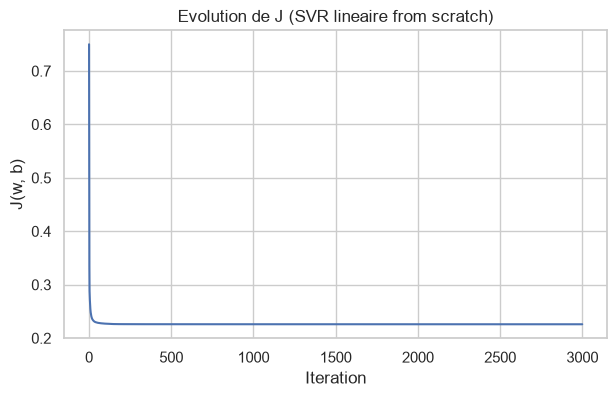

In [ ]:
eps = 0.1 # demi-largeur du tube en echelle standardisee
# on peut tester d'autres valeurs, par exemple 0.05 ou 0.2
svr_perso = SVRLineaire(epsilon=eps, lam=0.01, lr=0.1, n_iter=3000)
svr_perso.fit(X_train_np, ys_train)

# predictions (echelle standardisee puis retour en mpg)
pred_train_svr = vers_mpg(svr_perso.predict(X_train_np))
pred_test_svr = vers_mpg(svr_perso.predict(X_test_np))

print("SVR lineaire from scratch (epsilon =", eps, ")")
print("TRAIN -> MAE :", round(mae(y_train_np, pred_train_svr), 3),
      "| RMSE :", round(rmse(y_train_np, pred_train_svr), 3),
      "| R2 :", round(r2(y_train_np, pred_train_svr), 3))
print("TEST  -> MAE :", round(mae(y_test_np, pred_test_svr), 3),
      "| RMSE :", round(rmse(y_test_np, pred_test_svr), 3),
      "| R2 :", round(r2(y_test_np, pred_test_svr), 3))
print("Vecteurs de support :", svr_perso.n_support(X_train_np, ys_train), "sur", len(X_train_np))

plt.figure(figsize=(7, 4))
plt.plot(svr_perso.historique)
plt.title("Evolution de J (SVR lineaire from scratch)")
plt.xlabel("Iteration")
plt.ylabel("J(w, b)")
plt.show()

## 7.10 Comparaison avec scikit-learn

On utilise `SVR(kernel="linear", C=..., epsilon=...)` avec :
- le **même $\varepsilon$** (sur la même cible standardisée) ;
- le **même $C = \dfrac{1}{\lambda n}$**.

On attend des résultats **proches**
(mêmes métriques à peu près, mêmes signes pour les coefficients), mais pas identiques.

In [ ]:
from sklearn.svm import SVR # pour le SVR lineaire de scikit-learn

C_equiv = 1 / (0.01 * len(X_train_np)) # sert a calculer le C equivalent a notre lambda
# on peut tester d'autres valeurs de epsilon, par exemple 0.05 ou 0.2
svr_sk = SVR(kernel="linear", C=C_equiv, epsilon=eps)
svr_sk.fit(X_train_np, ys_train)
# predictions (echelle standardisee puis retour en mpg)
pred_train_sk = vers_mpg(svr_sk.predict(X_train_np))
pred_test_sk = vers_mpg(svr_sk.predict(X_test_np))

print("SVR lineaire scikit-learn (epsilon =", eps, ")")
print("TRAIN -> MAE :", round(mae(y_train_np, pred_train_sk), 3),
      "| RMSE :", round(rmse(y_train_np, pred_train_sk), 3),
      "| R2 :", round(r2(y_train_np, pred_train_sk), 3))
print("TEST  -> MAE :", round(mae(y_test_np, pred_test_sk), 3),
      "| RMSE :", round(rmse(y_test_np, pred_test_sk), 3),
      "| R2 :", round(r2(y_test_np, pred_test_sk), 3))
print("Vecteurs de support :", len(svr_sk.support_), "sur", len(X_train_np))

# ecart moyen entre les predictions des deux modeles (en mpg)
print("\nEcart moyen entre les predictions (test) :",
      round(np.mean(np.abs(pred_test_svr - pred_test_sk)), 3), "mpg")

SVR lineaire scikit-learn (epsilon = 0.1 )
TRAIN -> MAE : 2.489 | RMSE : 3.412 | R2 : 0.815
TEST  -> MAE : 2.366 | RMSE : 3.347 | R2 : 0.78
Vecteurs de support : 247 sur 313

Ecart moyen entre les predictions (test) : 0.064 mpg


## 7.11 Comparer les coefficients et visualiser les prédictions

1. **Coefficients** : on compare $w$ et $b$ des deux modèles. Les coefficients sont exprimés
   en unités standardisées, donc comparables entre variables : plus $|w_j|$ est grand, plus la variable pèse.
2. **Graphique prédit vs réel** : si le modèle était parfait, tous les points seraient sur la
   diagonale $y=x$. Plus le nuage s'écarte de la diagonale, plus l'erreur est grande.

     feature  w from scratch  w scikit-learn
   cylinders          -0.075          -0.088
displacement          -0.030           0.012
  horsepower          -0.103          -0.105
      weight          -0.441          -0.459
acceleration          -0.071          -0.067
  model_year           0.295           0.299
origin_japan           0.209           0.207
  origin_usa          -0.245          -0.255

b from scratch : 0.082
b scikit-learn : 0.095


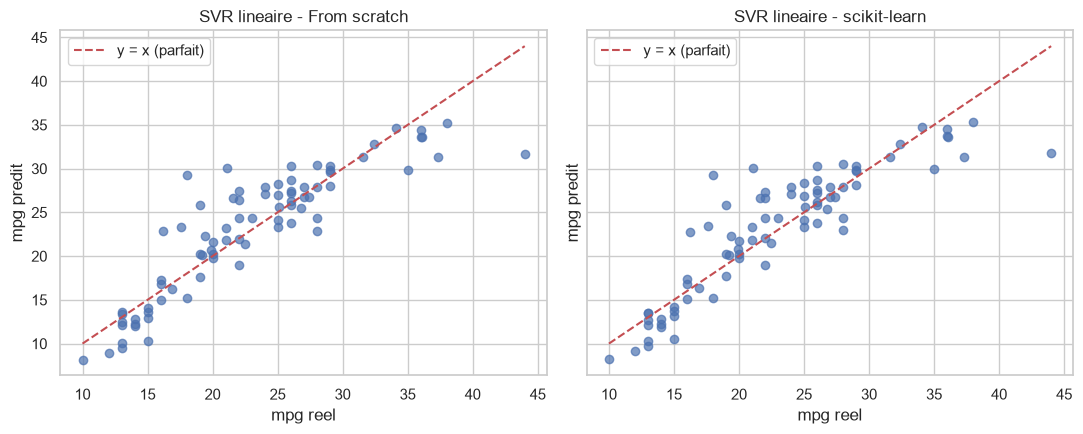

In [44]:
# 1) coefficients
comparaison_w = pd.DataFrame({
    "feature": noms_features,
    "w from scratch": np.round(svr_perso.w, 3),
    "w scikit-learn": np.round(svr_sk.coef_.ravel(), 3),
})
print(comparaison_w.to_string(index=False))
print("\nb from scratch :", round(svr_perso.b, 3))
print("b scikit-learn :", round(svr_sk.intercept_[0], 3))

# 2) predit vs reel sur le test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, pred, titre in zip(axes, [pred_test_svr, pred_test_sk], ["From scratch", "scikit-learn"]):
    ax.scatter(y_test_np, pred, alpha=0.7)
    lim = [y_test_np.min(), y_test_np.max()]
    ax.plot(lim, lim, "r--", label="y = x (parfait)")   # diagonale
    ax.set_title("SVR lineaire - " + titre)
    ax.set_xlabel("mpg reel")
    ax.set_ylabel("mpg predit")
    ax.legend()
plt.tight_layout()
plt.show()

# Partie 8 : Influence du paramètre ε

## 8.1 Ce qu'on s'attend à observer

Rappel : le tube a une largeur $2\varepsilon$, et seuls les points **sur le bord ou hors du tube**
sont des vecteurs de support.

| ε | Tube | Vecteurs de support | Risque |
|---|------|---------------------|--------|
| **petit** (proche de 0) | très étroit | **beaucoup** (presque tous les points) | le modèle essaie de coller à chaque point, **bruit compris** |
| **moyen** | adapté au bruit | un nombre raisonnable | bon compromis |
| **grand** | très large | **très peu**, voire aucun | le modèle devient trop plat (**sous-apprentissage**) : il prédit presque la moyenne |

**Lien avec le bruit** : si le bruit des données a une amplitude d'environ $\sigma$, choisir
$\varepsilon$ de l'ordre de $\sigma$ permet au modèle d'**ignorer** les petites fluctuations
aléatoires (elles restent dans le tube, donc sans influence) et de ne réagir qu'aux vraies tendances.

**Cas limite $\varepsilon=0$** : tous les points hors de la droite pèsent, la perte devient
$|r|$ (erreur absolue). Pas de tube, donc aucune "ignorance" du bruit.

On rappelle que $\varepsilon$ est exprimé en **écarts-types de mpg**.

## 8.2 Expérience 1 : balayage de ε sur les données réelles

On entraîne un SVR (notre version **et** celle de scikit-learn) pour plusieurs valeurs de ε.
Pour chacune, on relève :
- le **nombre de vecteurs de support** ;
- la **MAE sur le test** (en mpg) et le $R^2$ sur le test.

**Remarque sur notre comptage** : la descente de gradient n'atterrit jamais exactement sur le bord
du tube, donc on compte comme "support" les points avec $|r| \ge \varepsilon - \text{tol}$.
On prend ici une tolérance de 0,01 (un peu plus large qu'avant). Notre nombre reste donc **approché**,
alors que celui de scikit-learn est **exact**. On s'intéresse surtout à la **tendance**.

In [ ]:
# valeurs de epsilon a tester (en ecarts-types de mpg)
liste_eps = [0.0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.2]

C_equiv = 1 / (0.01 * len(X_train_np))

lignes = []
for e in liste_eps: # on fait tourner le modele pour chaque epsilon
    # notre modele
    m = SVRLineaire(epsilon=e, lam=0.01, lr=0.1, n_iter=3000)
    m.fit(X_train_np, ys_train)
    pred_m = vers_mpg(m.predict(X_test_np))

    # modele scikit-learn
    s = SVR(kernel="linear", C=C_equiv, epsilon=e)
    s.fit(X_train_np, ys_train)
    pred_s = vers_mpg(s.predict(X_test_np))
# on stocke les resultats dans une liste de listes, pour ensuite creer un DataFrame
    lignes.append([e,
                   m.n_support(X_train_np, ys_train, tol=0.01),
                   len(s.support_),
                   mae(y_test_np, pred_m),
                   mae(y_test_np, pred_s),
                   r2(y_test_np, pred_m),
                   r2(y_test_np, pred_s)])

etude_eps = pd.DataFrame(lignes, columns=["epsilon", "SV scratch", "SV sklearn",
                                          "MAE scratch", "MAE sklearn",
                                          "R2 scratch", "R2 sklearn"])
print(etude_eps.round(3).to_string(index=False))
print("\nNombre de points d'entrainement :", len(X_train_np))

 epsilon  SV scratch  SV sklearn  MAE scratch  MAE sklearn  R2 scratch  R2 sklearn
    0.00         313         313        2.357        2.368       0.780       0.779
    0.05         286         280        2.344        2.348       0.783       0.784
    0.10         251         247        2.384        2.366       0.777       0.780
    0.20         194         189        2.376        2.373       0.788       0.789
    0.40          99          98        2.390        2.427       0.797       0.797
    0.80          27          24        2.705        2.948       0.759       0.742
    1.20           6           5        3.556        3.409       0.631       0.654

Nombre de points d'entrainement : 313


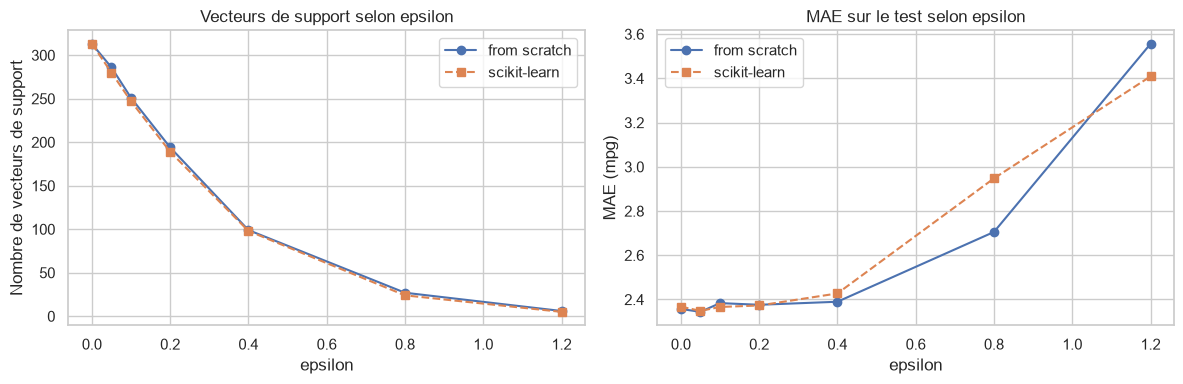

In [ ]:
# visualisation : nombre de vecteurs de support et erreur en fonction de epsilon
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# on peut utiliser des symboles differents pour les deux modeles, et des lignes pleines ou en pointilles
axes[0].plot(etude_eps["epsilon"], etude_eps["SV scratch"], "o-", label="from scratch")
axes[0].plot(etude_eps["epsilon"], etude_eps["SV sklearn"], "s--", label="scikit-learn")
axes[0].set_title("Vecteurs de support selon epsilon")
axes[0].set_xlabel("epsilon")
axes[0].set_ylabel("Nombre de vecteurs de support")
axes[0].legend()
# on peut utiliser des symboles differents pour les deux modeles, et des lignes pleines ou en pointilles
axes[1].plot(etude_eps["epsilon"], etude_eps["MAE scratch"], "o-", label="from scratch")
axes[1].plot(etude_eps["epsilon"], etude_eps["MAE sklearn"], "s--", label="scikit-learn")
axes[1].set_title("MAE sur le test selon epsilon")
axes[1].set_xlabel("epsilon")
axes[1].set_ylabel("MAE (mpg)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8.3 Expérience 2 : voir le tube en 1D

Avec 7 variables, on ne peut pas dessiner le tube. On fabrique donc un petit exemple
**en une seule dimension**, où l'on connaît la vraie droite :

$$y = 1{,}5\,x + 1 + \text{bruit}, \qquad \text{bruit} \sim \mathcal N(0;\,0{,}5^2)$$

On entraîne notre SVR avec 3 valeurs de ε (petit, proche du bruit, grand) et on trace :
- la droite apprise (en rouge) ;
- le tube $\pm\varepsilon$ autour d'elle (en pointillés) ;
- les **vecteurs de support** (entourés).

Comme le bruit a un écart-type de 0,5, le tube $\varepsilon \approx 0{,}5$ doit englober une bonne
partie des points : le modèle ignore alors leurs petites fluctuations.

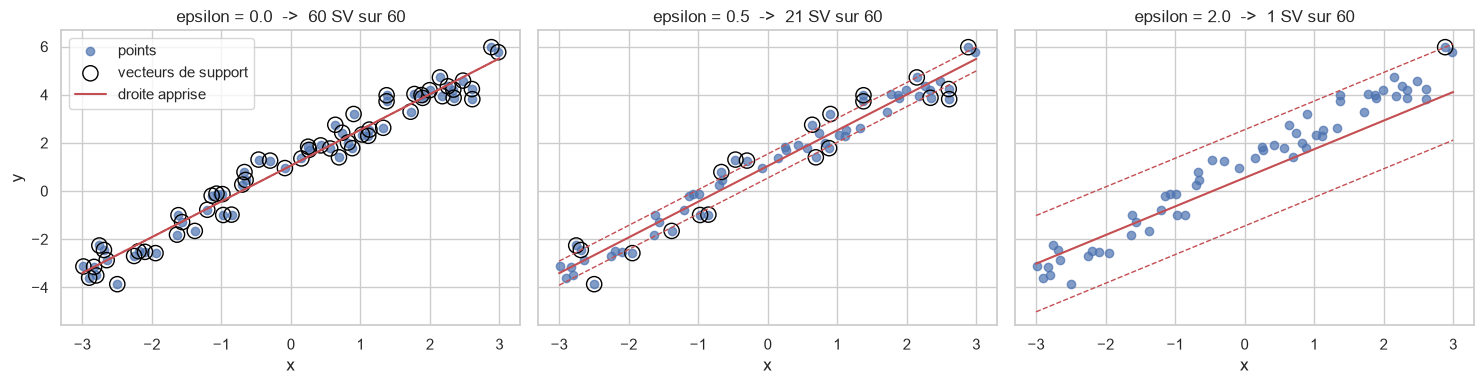

In [ ]:
# donnees artificielles : une vraie droite + du bruit gaussien
rng = np.random.default_rng(0)          # generateur aleatoire avec graine fixe
n_demo = 60
x_demo = rng.uniform(-3, 3, n_demo)
y_demo = 1.5 * x_demo + 1 + rng.normal(0, 0.5, n_demo)   # bruit d'ecart-type 0.5
X_demo = x_demo.reshape(-1, 1)          # notre classe attend une matrice (n, d)

x_ligne = np.linspace(-3, 3, 100).reshape(-1, 1)   # pour tracer la droite

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
# on teste trois valeurs de epsilon : 0.0, 0.5 et 2.0
for ax, e in zip(axes, [0.0, 0.5, 2.0]):
    m = SVRLineaire(epsilon=e, lam=0.01, lr=0.1, n_iter=3000)
    m.fit(X_demo, y_demo)

    droite = m.predict(x_ligne)
    r = y_demo - m.predict(X_demo)
    est_sv = np.abs(r) >= e - 0.01          # vecteurs de support (approches)

    ax.scatter(x_demo, y_demo, alpha=0.7, label="points")
    # on entoure les vecteurs de support
    ax.scatter(x_demo[est_sv], y_demo[est_sv], s=120, facecolors="none",
               edgecolors="black", label="vecteurs de support")
    ax.plot(x_ligne, droite, "r-", label="droite apprise")
    ax.plot(x_ligne, droite + e, "r--", linewidth=1)    # bord haut du tube
    ax.plot(x_ligne, droite - e, "r--", linewidth=1)    # bord bas du tube
    ax.set_title("epsilon = " + str(e) + "  ->  " + str(est_sv.sum()) + " SV sur " + str(n_demo))
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 8.4 Expérience 3 : robustesse au bruit sur les données réelles

On va tester la capacité du SVR à **ignorer le bruit** sur les vraies données.

**Protocole**
1. On **abîme volontairement** la cible d'entraînement `ys_train` en lui ajoutant :
   - un bruit gaussien d'écart-type 0,3 sur tous les points ;
   - des **valeurs aberrantes** (*outliers*) sur 5 % des points : un décalage de ±2.
2. On entraîne chaque modèle sur ces données bruitées.
3. On évalue sur le **test propre** (non bruité) : on mesure ce que le modèle a appris de la vraie relation.
4. On compare le SVR (plusieurs ε) aux **moindres carrés** (régression linéaire classique, résolue avec `np.linalg.lstsq`).

On répète l'opération **10 fois** avec des tirages de bruit différents, et on moyenne : une seule
expérience pourrait être trompeuse à cause du hasard.

In [ ]:
def moindres_carres(X, y):
    """Regression lineaire classique : renvoie (w, b)."""
    # on ajoute une colonne de 1 pour le biais b
    Xb = np.column_stack([X, np.ones(len(X))])
    coef = np.linalg.lstsq(Xb, y, rcond=None)[0]
    return coef[:-1], coef[-1]

# on va tester la robustesse du SVR lineaire par rapport a la regression lineaire classique
n_rep = 10
eps_bruit = [0.0, 0.1, 0.3, 0.5, 1.0]
rng = np.random.default_rng(1)

# on stocke la MAE test de chaque repetition
res_svr = {e: [] for e in eps_bruit}
res_mc = []
# on fait tourner le test plusieurs fois pour avoir une moyenne et un ecart-type
for rep in range(n_rep):
    # 1) cible abimee : bruit gaussien + quelques outliers
    y_bruit = ys_train + rng.normal(0, 0.3, len(ys_train))
    idx_out = rng.choice(len(ys_train), size=int(0.05 * len(ys_train)), replace=False)
    y_bruit[idx_out] += rng.choice([-2, 2], size=len(idx_out))

    # 2) moindres carres
    w_mc, b_mc = moindres_carres(X_train_np, y_bruit)
    pred_mc = vers_mpg(X_test_np @ w_mc + b_mc)
    res_mc.append(mae(y_test_np, pred_mc))

    # 3) SVR pour chaque epsilon
    for e in eps_bruit:
        m = SVRLineaire(epsilon=e, lam=0.01, lr=0.1, n_iter=3000)
        m.fit(X_train_np, y_bruit)
        res_svr[e].append(mae(y_test_np, vers_mpg(m.predict(X_test_np))))

# moyenne et ecart-type sur les repetitions
print("MAE test (mpg), moyenne +- ecart-type sur", n_rep, "repetitions")
print("Moindres carres :", round(np.mean(res_mc), 3), "+-", round(np.std(res_mc), 3))
for e in eps_bruit:
    print("SVR epsilon =", e, ":", round(np.mean(res_svr[e]), 3), "+-", round(np.std(res_svr[e]), 3))

MAE test (mpg), moyenne +- ecart-type sur 10 repetitions
Moindres carres : 2.51 +- 0.108
SVR epsilon = 0.0 : 2.379 +- 0.076
SVR epsilon = 0.1 : 2.395 +- 0.073
SVR epsilon = 0.3 : 2.39 +- 0.051
SVR epsilon = 0.5 : 2.426 +- 0.064
SVR epsilon = 1.0 : 2.799 +- 0.21


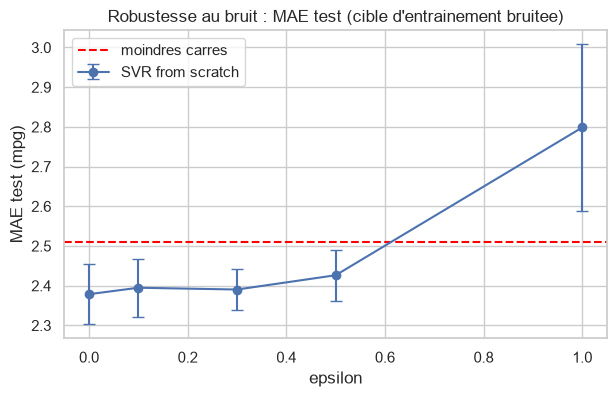

In [49]:
# graphique : MAE test selon epsilon, avec la ligne des moindres carres
moy = [np.mean(res_svr[e]) for e in eps_bruit]
std = [np.std(res_svr[e]) for e in eps_bruit]

plt.figure(figsize=(7, 4))
plt.errorbar(eps_bruit, moy, yerr=std, fmt="o-", capsize=4, label="SVR from scratch")
plt.axhline(np.mean(res_mc), color="red", linestyle="--", label="moindres carres")
plt.title("Robustesse au bruit : MAE test (cible d'entrainement bruitee)")
plt.xlabel("epsilon")
plt.ylabel("MAE test (mpg)")
plt.legend()
plt.show()

## 8.5 Synthèse à rédiger

À partir de tes résultats, tu dois pouvoir écrire ces trois conclusions (avec tes chiffres) :

1. **ε et vecteurs de support** : quand ε augmente, le nombre de vecteurs de support
   (diminue / augmente) car le tube (s'élargit / se rétrécit) et de plus en plus de points
   sont (à l'intérieur / à l'extérieur) du tube.
2. **ε et qualité de la prédiction** : à partir de quelle valeur de ε la MAE test se dégrade-t-elle ?
   Pour ε très grand, que devient le $R^2$ et pourquoi ? (indice : le modèle devient presque constant.)
3. **ε et bruit** : le meilleur ε est-il nul, moyen ou grand ? Le SVR fait-il mieux que les moindres carrés
   sur des données bruitées ? Même s'il ne gagne que de peu, explique **pourquoi** il y a un avantage.

# Partie 9 : Récapitulatif et conclusion

On rassemble tous les résultats du notebook dans deux tableaux (un pour la classification,
un pour la régression).

Pour la classification, on **recalcule** les prédictions à partir des modèles déjà entraînés,
car certaines variables ont été réutilisées plus haut.

In [ ]:
# Tableau de classification
# on refait les predictions a partir des modeles (les variables pred_*_sk ont ete ecrasees a l'etape 7)
modeles_clf = {
    "SVC lineaire (from scratch)": svc_perso,
    "SVC lineaire (scikit-learn)": svc_sk,
    "SVC RBF (from scratch)": svc_rbf_perso,
    "SVC RBF (scikit-learn)": svc_rbf_sk,
}
# on calcule les accuracies sur le train et le test pour chaque modele
lignes = []
for nom, modele in modeles_clf.items():
    acc_tr = np.mean(modele.predict(X_train_np) == yc_train)
    acc_te = np.mean(modele.predict(X_test_np) == yc_test)
    lignes.append([nom, acc_tr, acc_te])

recap_clf = pd.DataFrame(lignes, columns=["Modele", "Acc. train", "Acc. test"])
print("CLASSIFICATION (3 classes, seuils par quantiles)")
print(recap_clf.round(3).to_string(index=False))

CLASSIFICATION (3 classes, seuils par quantiles)
                     Modele  Acc. train  Acc. test
SVC lineaire (from scratch)       0.741      0.544
SVC lineaire (scikit-learn)       0.770      0.582
     SVC RBF (from scratch)       0.831      0.810
     SVC RBF (scikit-learn)       0.853      0.797


In [ ]:
# Tableau recapitulatif : regression
# reference : regression lineaire classique (moindres carres) sur les donnees propres
w_mc0, b_mc0 = moindres_carres(X_train_np, ys_train)
pred_test_mc0 = vers_mpg(X_test_np @ w_mc0 + b_mc0)

# predictions test des deux SVR (epsilon = 0.1, etape 7)
pred_test_scratch = vers_mpg(svr_perso.predict(X_test_np))
pred_test_sklearn = vers_mpg(svr_sk.predict(X_test_np))
# on calcule les MAE, RMSE et R2 pour chaque modele
recap_reg = pd.DataFrame({
    "Modele": ["SVR lineaire (from scratch)", "SVR lineaire (scikit-learn)", "Moindres carres"],
    "MAE test": [mae(y_test_np, pred_test_scratch),
                 mae(y_test_np, pred_test_sklearn),
                 mae(y_test_np, pred_test_mc0)],
    "RMSE test": [rmse(y_test_np, pred_test_scratch),
                  rmse(y_test_np, pred_test_sklearn),
                  rmse(y_test_np, pred_test_mc0)],
    "R2 test": [r2(y_test_np, pred_test_scratch),
                r2(y_test_np, pred_test_sklearn),
                r2(y_test_np, pred_test_mc0)],
})
print("REGRESSION (epsilon = 0.1)")
print(recap_reg.round(3).to_string(index=False))

REGRESSION (epsilon = 0.1)
                     Modele  MAE test  RMSE test  R2 test
SVR lineaire (from scratch)     2.384      3.371    0.777
SVR lineaire (scikit-learn)     2.366      3.347    0.780
            Moindres carres     2.462      3.256    0.792


## 9.1 Conclusions

**Prétraitement**
- 6 lignes avec `horsepower` manquant supprimées (398 → 392).
- `origin` encodée en one-hot, les variables numériques standardisées avec les statistiques du **train uniquement** pour éviter la fuite de données.

**Classification**
- Discrétisation par **quantiles** : seuils à ... et ... mpg, classes équilibrées (... / ... / ...).
- SVC linéaire : accuracy test = ... (from scratch) contre ... (scikit-learn).
- SVC RBF : accuracy test = ... (from scratch) contre ... (scikit-learn).
- Le noyau RBF (améliore / n'améliore pas) le linéaire, car ...
- Les erreurs se concentrent entre classes **voisines**, près des seuils.

**Régression**
- SVR linéaire (ε = 0,1) : MAE test = ... mpg, R² = ... (from scratch) contre ... (scikit-learn).
- Quand ε augmente, le nombre de vecteurs de support (diminue / augmente) : de ... à ... .
- Pour ε très grand, le R² devient ..., le modèle prédit presque ...
- Face au bruit et aux outliers, le SVR (est / n'est pas) meilleur que les moindres carrés : ... contre ... mpg de MAE.

**Écarts avec scikit-learn**
Ils viennent de la méthode de résolution : scikit-learn résout le problème **dual** exactement,
nous utilisons une **descente de gradient** approchée avec un nombre fixé d'itérations.

# Partie 10 : Sources et répartition du travail

## 10.1 Sources et ressources

- Cours de Machine Learning (SVM, noyaux, SVR) et travaux dirigés associés.
- Documentation officielle de scikit-learn : https://scikit-learn.org/stable/modules/svm.html
- Jeu de données Auto MPG, chargé via `seaborn.load_dataset('mpg')`.
- Bibliothèques utilisées : numpy, pandas, matplotlib, seaborn, scikit-learn.

## 10.2 Répartition du travail

**Travail réalisé de manière autonome.**
J'ai réalisé la chaîne de traitement des données : chargement et nettoyage du jeu de données,
analyse exploratoire, encodage des variables catégorielles, standardisation, découpage
apprentissage/test, ainsi que la stratégie de discrétisation de la variable cible.
J'ai également mis en place les métriques d'évaluation, comparé mes modèles à ceux de
scikit-learn et rédigé l'interprétation des résultats et les conclusions.

**Travail réalisé avec l'appui d'un assistant IA (Claude).**
Pour les parties les plus techniques, j'ai sollicité un assistant IA afin de m'accompagner
dans la formulation mathématique et l'implémentation du SVC à noyau (représentation par
les coefficients α et matrice de Gram), du sous-gradient associé à la perte ε-insensible
du SVR, ainsi que dans la conception du protocole d'étude de la robustesse au bruit.
Ce code a ensuite été relu, testé, adapté et validé par comparaison avec les
implémentations de scikit-learn.

**Autres usages de l'assistant.**
L'outil a également servi à clarifier certaines notions théoriques et à améliorer la
formulation de certains passages rédigés.